# Prédire six indicateurs thermiques d'un bâtiment à partir d'un essai de 8 h

*Assessment de stage coEnergy — Fares — novembre 2026*

**Tâche.** À partir de $T_{int}(t)$ et $U(t)$ (480 pas d'une minute), prédire $y = [\mathrm{HLC},\ \mathrm{HLC}_{ext},\ \mathrm{HLC}_{mit},\ \tau_b,\ \tau_n,\ \tau_\infty]$, avec la contrainte $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$.

**En bref**
- **Données.** 1 000 000 de simulations d'un même bâtiment-type, chauffées par des PRBS 0 / 7 000 W. Elles ne contiennent que **2 798 excitations distinctes**, et 99,99 % des simulations de test reçoivent une excitation déjà vue à l'entraînement : le test évalue de nouveaux bâtiments, pas de nouvelles excitations (3.6).
- **Diagnostic.** Le problème inverse est mal posé. Sans chauffe, 99,8 % des maisons ont une « jumelle » dont la courbe diffère de moins de 0,05 °C, et leurs HLC diffèrent presque autant que ceux de deux maisons prises au hasard. Ce que la courbe dit de plus tient dans des détails de forme à l'échelle du bruit d'un capteur (3.7).
- **Modèle.** CNN-GRU de 210 000 paramètres. Sa tête garantit $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ et $\tau_n \le \tau_\infty \le \tau_b$ ; il prédit une moyenne et une variance par indicateur (vraisemblance gaussienne), et il est entraîné avec bruit capteur (5, 6.5).
- **Test** (30 000 simulations, une seule évaluation). HLC : $R^2$ = 0,39, erreur relative moyenne 8,5 %, 95 % des erreurs sous 48 W/K. $\mathrm{HLC}_{ext}$ : 0,32 ; $\tau_n$ : 0,22 ; $\tau_b$ et $\tau_\infty$ : < 0,1. Intervalles calibrés de 10 % à 99 % ; stable jusqu'à 0,10 °C de bruit (7).
- **Conclusion.** Cinq leviers (architecture, ×5 données, mesures parfaites, ensemble, spécialistes) gagnent au plus 0,02 de $R^2$. La limite est l'information de l'essai, pas le modèle ; le levier est la conception de l'excitation (6.6, 7.4, 8).

| Critère d'évaluation | Sections |
|---|---|
| 1. Compréhension physique, EDA | 1, 2, 3 (en particulier 3.6 et 3.7) |
| 2. Conception du modèle multi-indicateurs | 5 |
| 3. Protocole d'évaluation, métriques par famille, analyse critique | 4, 6, 7 |
| 5. Rédaction, modularité, ingénierie, reproductibilité | package `src/hlcnet/`, `tests/`, `README.md`, `uv.lock` |

**Exécution.** Le notebook importe toute sa logique de `hlcnet` et ne ré-entraîne rien : les modèles sont entraînés par `scripts/train.py` (GPU Kaggle) et évalués par `scripts/evaluate.py`, dont il relit les résultats (`artifacts/`). Il lit les données dans `data/quentin_house/` ; le premier passage sur le million de simulations prend quelques minutes, puis il est mis en cache.

In [1]:
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display

from hlcnet.data import SplitSpec, list_batches, load_batches
from hlcnet.eda import (
    conditional_correlation,
    excitation_features,
    full_consistency_checks,
    plot_batch_homogeneity,
    plot_correlation,
    plot_examples,
    plot_excitation_summary,
    plot_informativeness,
    plot_physical_relations,
    plot_target_distributions,
    sample_vs_population,
    scan_dataset,
    scan_features,
    scan_targets,
    target_table,
)
from hlcnet.identifiability import (
    excitation_coverage,
    excitation_groups_table,
    group_identical_excitations,
    ill_posedness_table,
    information_timeline,
    pca,
    pick_groups,
    plot_group_responses,
    plot_information_curve,
    plot_information_timelines,
    plot_pca,
    plot_twins,
    ridge_information_curve,
)
from hlcnet.metrics import family_summary
from hlcnet.report import (
    bias_corrected_r2,
    comparison_table,
    load_metrics,
    read_table,
    val_test_table,
)
from hlcnet.targets import TARGET_NAMES

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "quentin_house"
ARTIFACTS = ROOT / "artifacts"
RUNS = ARTIFACTS / "runs"
SEED = 0
torch.manual_seed(SEED)
pd.set_option("display.precision", 3)
%matplotlib inline

## 1. Le problème physique

**HLC.** Le *Heat Loss Coefficient* (W/K) est la puissance à fournir en continu pour maintenir l'intérieur 1 K au-dessus de son environnement. Dans l'article de coEnergy, le bâtiment est un modèle d'état $C\dot T = AT + EU,\ Y = JT + GU$, et le HLC est l'inverse du gain statique entre puissance injectée et température intérieure : $\mathrm{HLC} = 1/[G - JA^{-1}E]_{1,1}$. Il se décompose **exactement** par frontière : $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ (extérieur et espaces mitoyens).

**Constantes de temps** (définitions de l'énoncé), en heures :
- $\tau_b$ : relaxation libre après **saturation de toute la masse** du bâti ;
- $\tau_n$ : persistance de la fraîcheur après **8 h** de refroidissement de l'air ; elle dépend de la profondeur de pénétration du froid dans les parois ;
- $\tau_\infty$ : limite de $\tau_n$ pour une sollicitation infiniment longue.

Pour un modèle à une capacité, $\tau \approx C/\mathrm{HLC}$ : on attend des $\tau$ **anti-corrélées au HLC**, et $\tau_n \le \tau_\infty \le \tau_b$, puisque $\tau_n$ ne mobilise que la masse proche de l'air.

**Ce qu'un essai de 8 h peut révéler.** Avec $P = 7\,000$ W et $\mathrm{HLC} \approx 230$ W/K, l'élévation en régime permanent serait $P/\mathrm{HLC} \approx 30$ K ; on observe en moyenne environ 11 K. L'essai ne montre que le **début du transitoire**, et l'état initial des parois est inconnu. Deux prédictions physiques en découlent, vérifiées en section 7 :
- $\tau_n$, définie sur une sollicitation de 8 h comme l'essai, devrait être **la mieux identifiée** des trois constantes ;
- $\tau_b$ et $\tau_\infty$, qui font intervenir les modes lents de toute la masse (plusieurs dizaines d'heures), devraient être **à peine identifiables**.

## 2. Données

20 fichiers de 50 000 simulations. Chaque simulation fournit $T_{int}$ et $U$ (480 pas), les 6 cibles et les 12 paramètres de l'excitation (`solicitation`). Conventions :
- `Hb_labels` vaut `['HLC_mit', 'HLC_ext']` : les colonnes sont réordonnées **par nom** (`hlcnet.targets.assemble_targets`) ;
- comme dans l'exemple de l'énoncé, $T_{int}$ est arrondie à 0,01 °C et $U$ à 0,1 W ;
- le pas de temps n'est pas documenté : la durée des créneaux PRBS n'est compatible avec `prbs_min/max_duration_hours` que pour un pas d'**une minute**, soit 8 h par simulation ;
- les fichiers sont lus **un par un** (environ 4 Go au total).

**Deux niveaux d'analyse.** Tout ce qui se résume par simulation (cibles, contraintes, excitation, élévation de température) est calculé sur **le million de simulations** (`hlcnet.eda.scan_dataset`). Les analyses de courbes (3.1, 3.4, 3.6, 3.7) utilisent un échantillon de 50 000 simulations, dont on vérifie la représentativité.

In [2]:
files = list_batches(DATA)
SCAN = scan_dataset(DATA, cache=ARTIFACTS / "cache" / "scan_1M.pkl")
print(f"{len(files)} fichiers, {len(SCAN):,} simulations")
full_consistency_checks(SCAN).to_frame("valeur")

20 fichiers, 1,000,000 simulations


,valeur
simulations,1000000
simulations avec NaN,0
max |HLC - (ext + mit)| (W/K),0.0
part tau_b >= tau_inf >= tau_n,1.0
Tint(t=0) min / max (°C),24.62 / 24.62
U min / max (W),0.0 / 7000.0
HLC min / max (W/K),111 / 368
part sans chauffe,0.084


**Lecture.** Aucune valeur manquante sur le million de simulations. $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ exactement (écart maximal nul en float32), et $\tau_b \ge \tau_\infty \ge \tau_n$ dans **100 %** des simulations : deux contraintes que le modèle devra respecter. $T_{int}(0)$ vaut 24,62 °C partout : le niveau initial ne porte aucune information, seule la dynamique compte. $U \in [0, 7\,000]$ W : chauffage uniquement. Le HLC va de 111 à 368 W/K.

In [3]:
eda = load_batches(DATA, batch_ids=None, per_batch=2_500, seed=SEED)  # échantillon pour les courbes
print("échantillon :", tuple(eda.x.shape))
sample_vs_population(SCAN, eda)

échantillon : (50000, 480, 2)


,moyenne (1 M),moyenne (échantillon),écart-type (1 M),écart-type (échantillon),KS p-value
HLC,232.926,233.024,31.329,31.214,0.767
HLC_ext,112.438,112.480,17.112,17.174,0.648
HLC_mit,120.488,120.545,26.256,26.142,0.572
tau_b,50.001,49.962,10.097,10.065,0.673
tau_n,11.039,11.037,2.009,2.008,0.707
tau_inf,31.231,31.206,7.530,7.493,0.689
energy_kwh,26.246,26.364,13.687,13.704,0.053
duty,0.469,0.471,0.244,0.245,0.053


**Lecture.** Moyennes et écarts-types de l'échantillon coïncident avec ceux du million de simulations à moins de 0,5 % près, et les p-values de Kolmogorov–Smirnov vont de 0,05 à 0,77 : aucun test ne rejette l'égalité des distributions au seuil de 5 %. L'échantillon est représentatif.

## 3. Analyse exploratoire

### 3.1 Exemples

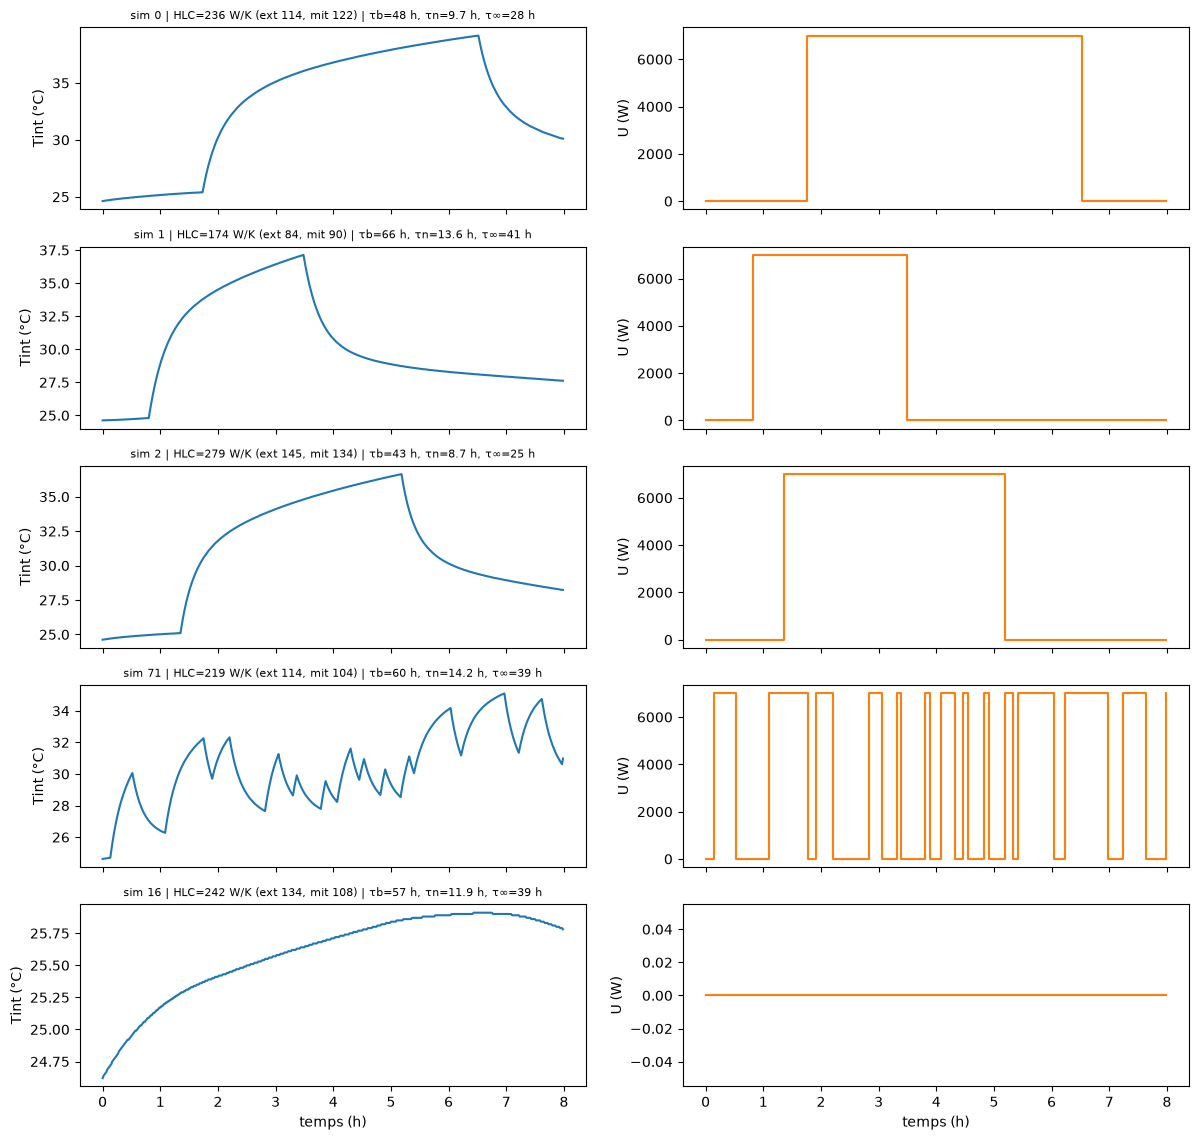

In [4]:
feats_eda = excitation_features(eda.x[..., 1])
never = torch.nonzero(feats_eda["never_on"]).squeeze(1)
busy = torch.nonzero(feats_eda["n_switch"] > 20).squeeze(1)
plot_examples(eda, [0, 1, 2, int(busy[0]), int(never[0])]);

**Lecture.** Toutes les excitations sont des **PRBS** : le chauffage alterne entre 0 et 7 000 W par créneaux de durée aléatoire. Selon les paramètres, on obtient un créneau long, des commutations rapides ou **aucune chauffe**. Même sans chauffe, $T_{int}$ dérive : les parois, initialement hors équilibre, relaxent.

### 3.2 Les indicateurs

,unité,count,mean,std,min,5%,50%,95%,max,skew
HLC,W/K,1000000.0,232.93,31.33,111.40,183.24,231.80,286.37,368.00,0.18
HLC_ext,W/K,1000000.0,112.44,17.11,52.65,84.74,112.19,141.04,185.89,0.10
HLC_mit,W/K,1000000.0,120.49,26.26,42.84,80.18,118.90,166.25,231.53,0.28
tau_b,h,1000000.0,50.00,10.10,20.20,35.64,48.82,68.36,122.88,0.71
tau_n,h,1000000.0,11.04,2.01,5.17,8.21,10.79,14.72,25.84,0.75
tau_inf,h,1000000.0,31.23,7.53,10.48,20.86,30.20,45.10,93.12,0.85


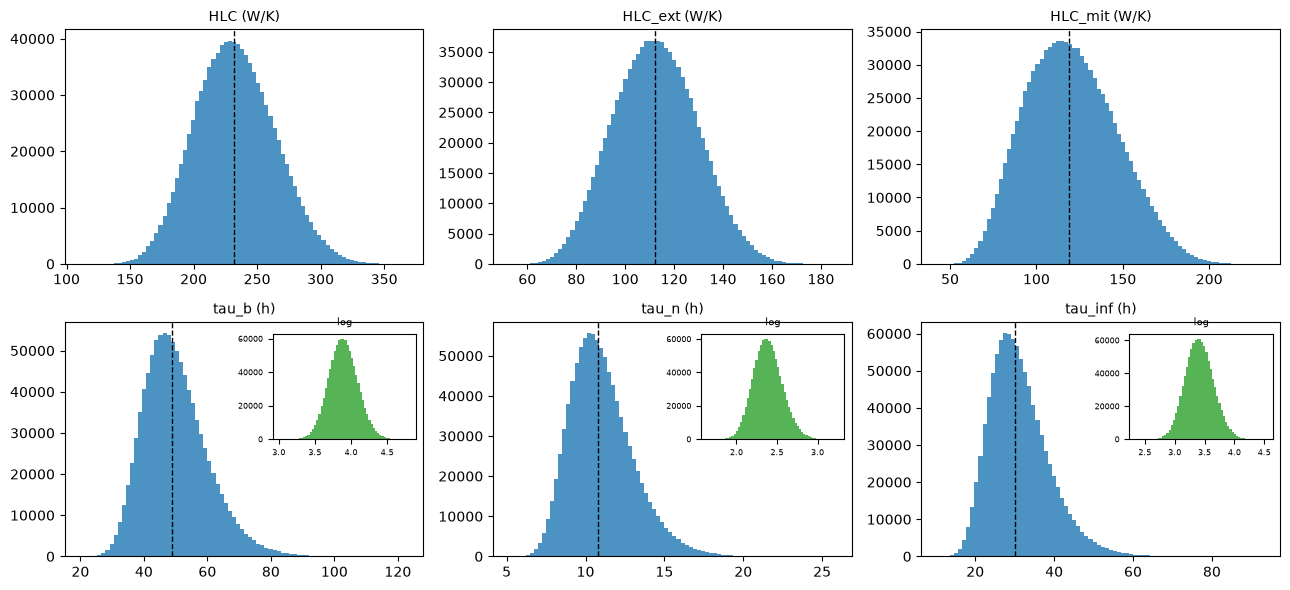

In [5]:
Y = scan_targets(SCAN)
display(target_table(Y))
plot_target_distributions(Y);

**Lecture.** Le HLC (moyenne 233 W/K, écart-type 31) et ses composantes ont des distributions en cloche (asymétrie ≤ 0,3). Les $\tau$ sont **asymétriques à droite** (asymétrie 0,7 à 0,85 ; $\tau_b$ : moyenne 50 h, $\tau_n$ : 11 h, $\tau_\infty$ : 31 h), et leur logarithme est presque symétrique (encarts) : on modélisera $\log\tau$. Les échelles diffèrent d'un facteur 20 (W/K contre h) : les cibles seront standardisées.

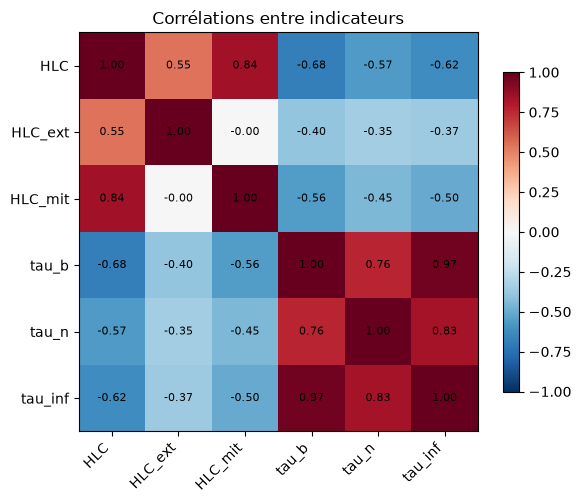

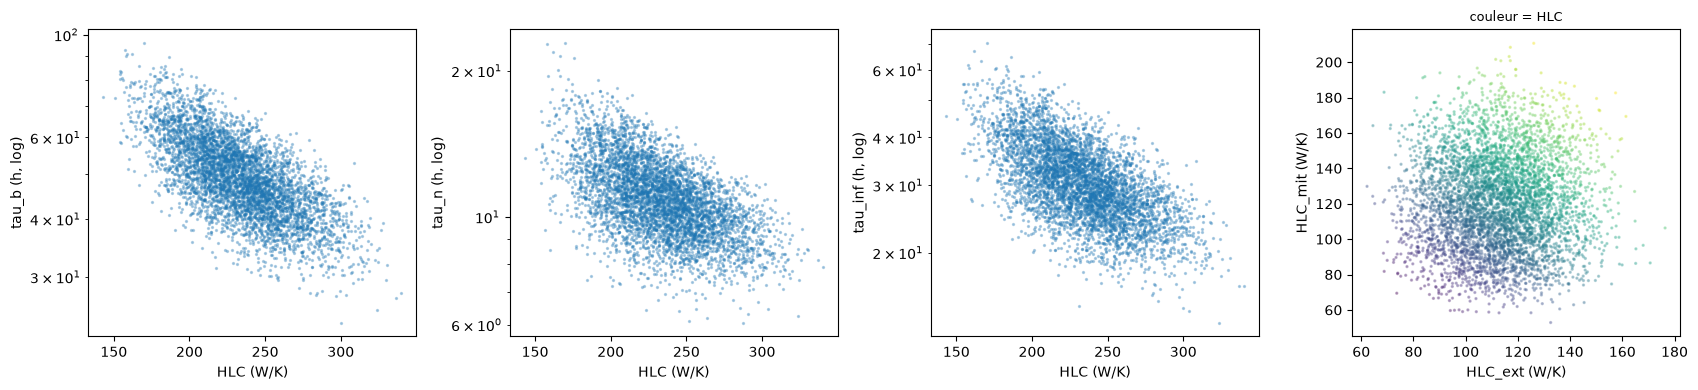

In [6]:
plot_correlation(Y)
plot_physical_relations(Y);

**Lecture.**
- Les $\tau$ sont **anti-corrélées au HLC** (−0,57 à −0,68), comme $\tau \approx C/\mathrm{HLC}$ le prévoit ; le reste de leur dispersion vient des capacités thermiques.
- $\tau_b$ et $\tau_\infty$ sont quasi colinéaires (0,97). $\tau_n$ l'est moins : elle ne dépend que des couches proches de l'air.
- $\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$ sont **décorrélés**, (corrélation nulle) et la variance du HLC vient surtout de $\mathrm{HLC}_{mit}$ (corrélation 0,84 contre 0,55). Connaître le HLC ne dit rien de sa répartition : prédire $H_b$ est un problème à part entière.

### 3.3 L'excitation

Sans aucune chauffe : 8.4% | chauffe continue : 0.9%
Énergie injectée moyenne : 26.2 kWh en 8 h


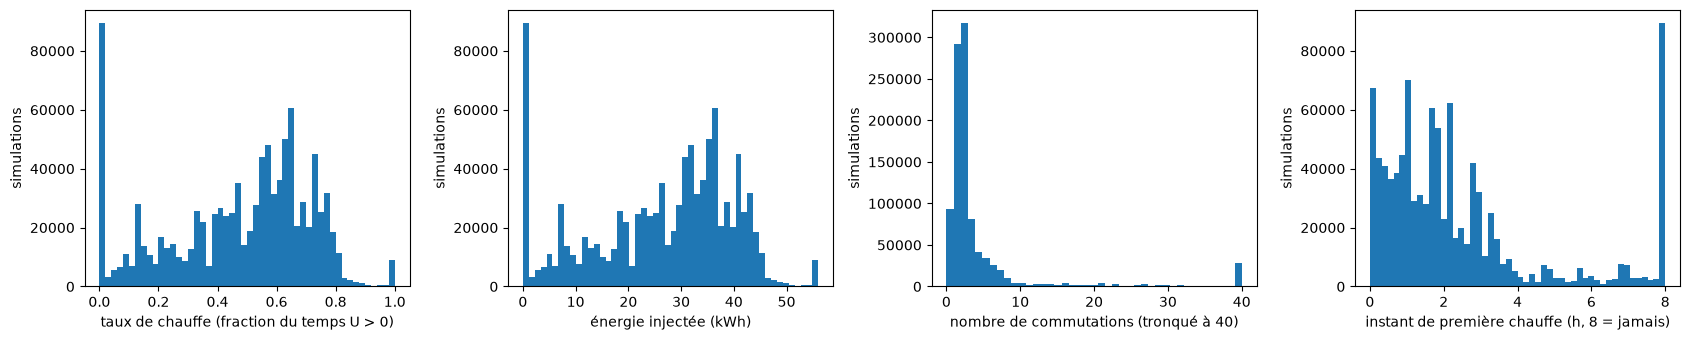

In [7]:
feats = scan_features(SCAN)
print(f"Sans aucune chauffe : {feats['never_on'].float().mean():.1%} | chauffe continue : {(feats['duty'] == 1).float().mean():.1%}")
print(f"Énergie injectée moyenne : {feats['energy_kwh'].mean():.1f} kWh en 8 h")
plot_excitation_summary(feats);

**Lecture.** Seuls deux paramètres varient : la probabilité d'allumage (0,2 à 0,9) et la durée minimale des créneaux (0 à 2 h) ; la puissance (7 000 W) et la graine (42) sont fixes. Les distributions sont multimodales : la plupart des signaux n'ont que 1 à 4 commutations, **8,4 % ne chauffent jamais** et 0,9 % chauffent en continu. Pour ceux-ci, le modèle ne voit qu'une évolution libre : on les analysera séparément (7.3).

### 3.4 Que dit la réponse sur le HLC ?

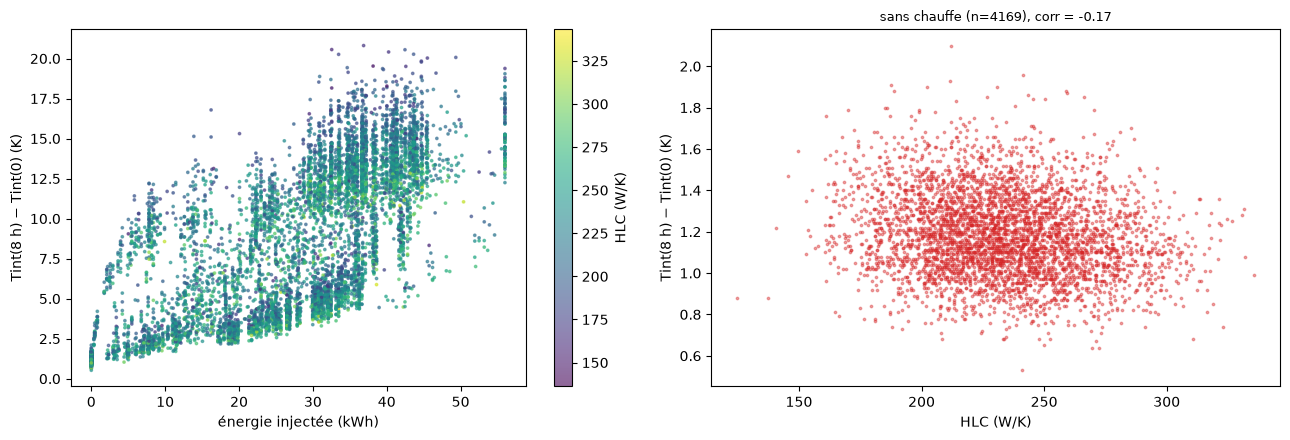

In [8]:
plot_informativeness(eda);

**Lecture.**
- **À gauche.** L'élévation finale dépend d'abord de l'énergie injectée, puis du **moment** de l'injection : à énergie égale, deux branches séparent les signaux encore en chauffe à 8 h de ceux arrêtés plus tôt. L'effet du HLC est invisible à l'œil, de second ordre devant la forme de l'excitation.
- **À droite.** Sans chauffe, $T_{int}$ monte d'environ 1,2 K (relaxation des parois), presque indépendamment du HLC (corrélation ≈ −0,17).

Pour isoler l'effet du HLC, on corrèle élévation finale et HLC **à énergie injectée comparable** (déciles d'énergie, simulations chauffées, un million de simulations) :

In [9]:
heated = ~SCAN["never_on"]
conditional_correlation(
    torch.tensor(SCAN.loc[heated, "energy_kwh"].to_numpy()),
    torch.tensor(SCAN.loc[heated, "rise"].to_numpy()),
    torch.tensor(SCAN.loc[heated, "HLC"].to_numpy()),
    n_bins=10,
)

,bin,min,max,n,corr
0,1,0.117,10.267,91544,-0.078
1,2,10.267,18.433,91189,-0.118
2,3,18.433,23.100,90640,-0.112
3,4,23.100,27.067,92175,-0.130
4,5,27.067,31.033,87176,-0.154
5,6,31.033,33.600,95596,-0.156
6,7,33.600,36.050,92494,-0.213
7,8,36.050,38.383,88333,-0.253
8,9,38.383,42.000,91230,-0.353
9,10,42.000,56.000,95459,-0.361


**Lecture.** La corrélation est **négative dans chaque décile** (un bâtiment plus déperditif s'échauffe moins) mais **faible**, de −0,08 à −0,36, et elle croît avec l'énergie : plus on chauffe, plus l'essai est informatif. Même dans le meilleur décile, l'élévation finale n'explique qu'environ 13 % de la variance du HLC. Un résumé statique ne suffit pas : l'information est dans la **forme temporelle** de la réponse, ce qui motive un modèle séquentiel.

### 3.5 Homogénéité des 20 fichiers

`scripts/compare_batches.py` compare les fichiers : proportions d'excitations, énergie, cibles, et tests de Kolmogorov–Smirnov de chaque fichier contre le premier.

Tests KS avec p < 0,01 : 0 / 114


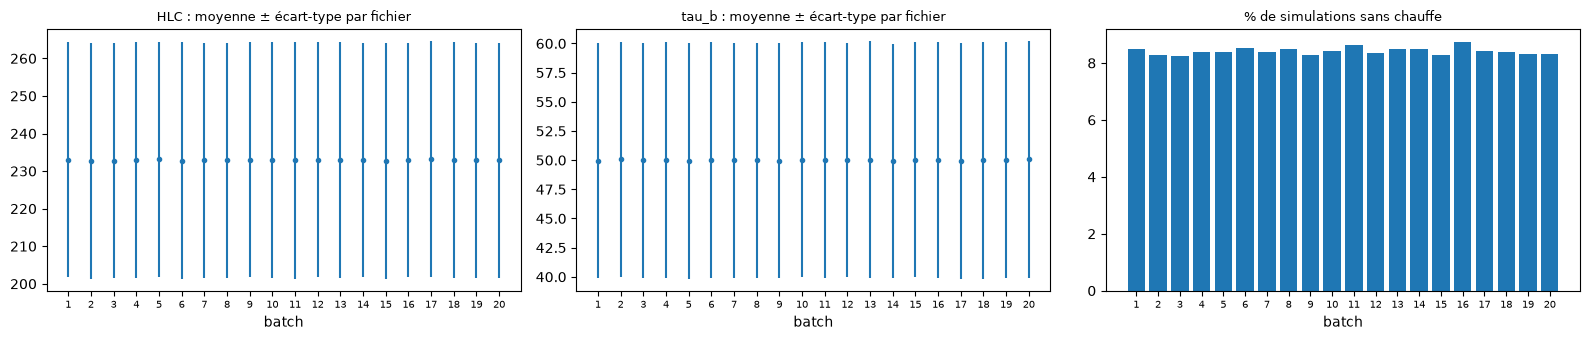

In [10]:
summary = pd.read_csv(ARTIFACTS / "batch_summary.csv")
ks_cols = [c for c in summary.columns if c.startswith("ks_p_")]
n_low = int((summary[ks_cols].iloc[1:] < 0.01).sum().sum())
print(f"Tests KS avec p < 0,01 : {n_low} / {len(ks_cols) * (len(summary) - 1)}")
plot_batch_homogeneity(summary);

**Lecture.** Les 20 fichiers sont **indiscernables** : moyenne du HLC entre 232,7 et 233,2 W/K (écart-type 31 W/K), part sans chauffe entre 8,3 et 8,7 %, et aucun des 114 tests KS significatif à 1 % (environ 1 attendu par hasard). On peut donc découper **par fichier** sans biais (section 4).

### 3.6 Identifiabilité : quelle information les courbes contiennent-elles, et quand ?

Question décisive pour la modélisation : pour chaque indicateur, quelle part de l'information est présente dans 8 h de mesure, et à quel moment ? Trois analyses sans réseau de neurones y répondent.

#### a) Expériences naturelles : même excitation, bâtiments différents

La graine du PRBS vaut toujours 42 : des paramètres voisins produisent des signaux **identiques à la minute près**. On compte les excitations distinctes du million de simulations grâce à une empreinte de chaque signal (`hlcnet.eda.excitation_hash`).

In [11]:
excitation_coverage(SCAN, SplitSpec())

,simulations,excitations distinctes,simulations dont l'excitation existe en train (%),excitations absentes du train
train,700000.0,2780.0,100.000,0.0
val,150000.0,2576.0,99.994,7.0
test,150000.0,2599.0,99.989,13.0
total,1000000.0,2798.0,NaN,NaN


**Lecture.** L'énoncé décrit chaque simulation comme « un scénario unique de sollicitation » ; en réalité, le million de simulations ne compte que **2 798 excitations distinctes**, soit environ 360 simulations par excitation. Seules 7 excitations de validation et 13 de test sont absentes de l'entraînement : 99,99 % des simulations de test reçoivent une excitation déjà vue. Deux conséquences :
- le test mesure la généralisation à de **nouveaux bâtiments**, pas à de nouvelles excitations (limite discutée en 7.6) ;
- à l'intérieur d'un groupe d'excitation identique, **toute différence de $T_{int}$ vient du bâtiment** : une expérience contrôlée, qui reproduit le cadre de la phase 2 de l'article (une excitation imposée, une population de bâtiments).

On étudie trois de ces groupes dans l'échantillon : jamais chauffé, chauffe continue (réponse indicielle) et le PRBS le plus fréquent.

In [12]:
u_eda = eda.x[..., 1]
group, sizes = group_identical_excitations(u_eda)
groups_tbl = excitation_groups_table(u_eda, group, sizes, top=10)
chosen = pick_groups(groups_tbl, sizes)
print({name: int(sizes[g]) for name, g in chosen.items()})
groups_tbl

{'Jamais chauffé': 4169, 'Chauffe continue (réponse indicielle)': 461, 'PRBS le plus fréquent': 749}


,groupe,taille,type,taux de chauffe,commutations,énergie (kWh)
0,0,4169,jamais chauffé,0.000,0,0.0
1,1,749,PRBS,0.656,1,36.8
2,2,676,PRBS,0.654,1,36.6
3,3,466,PRBS,0.738,1,41.3
4,4,461,chauffe continue,1.000,0,56.0
5,5,455,PRBS,0.581,1,32.5
6,6,447,PRBS,0.579,1,32.4
7,7,442,PRBS,0.621,1,34.8
8,8,310,PRBS,0.619,1,34.7
9,9,310,PRBS,0.665,1,37.2


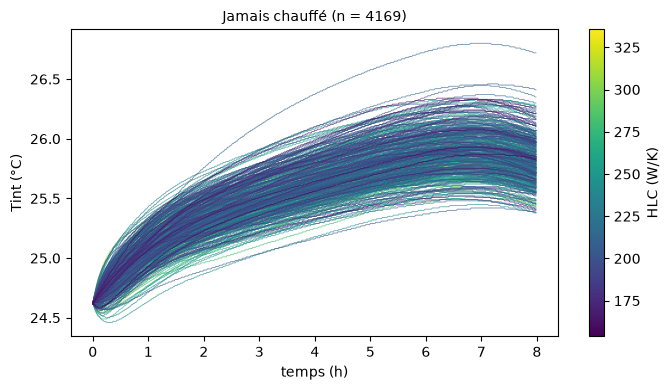

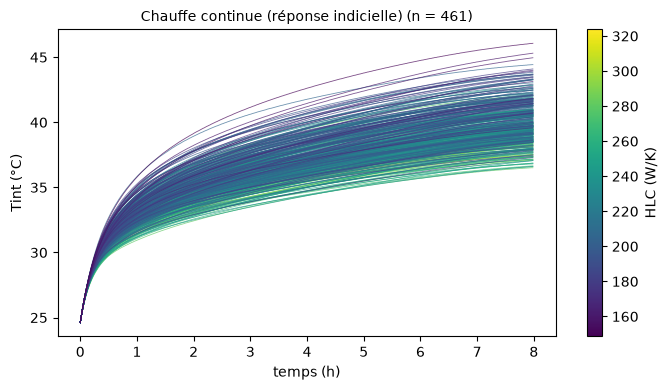

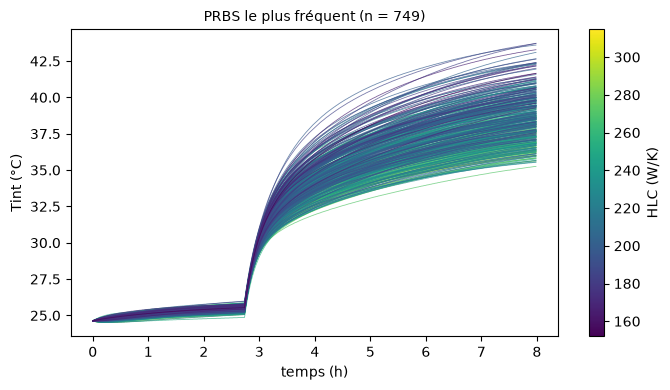

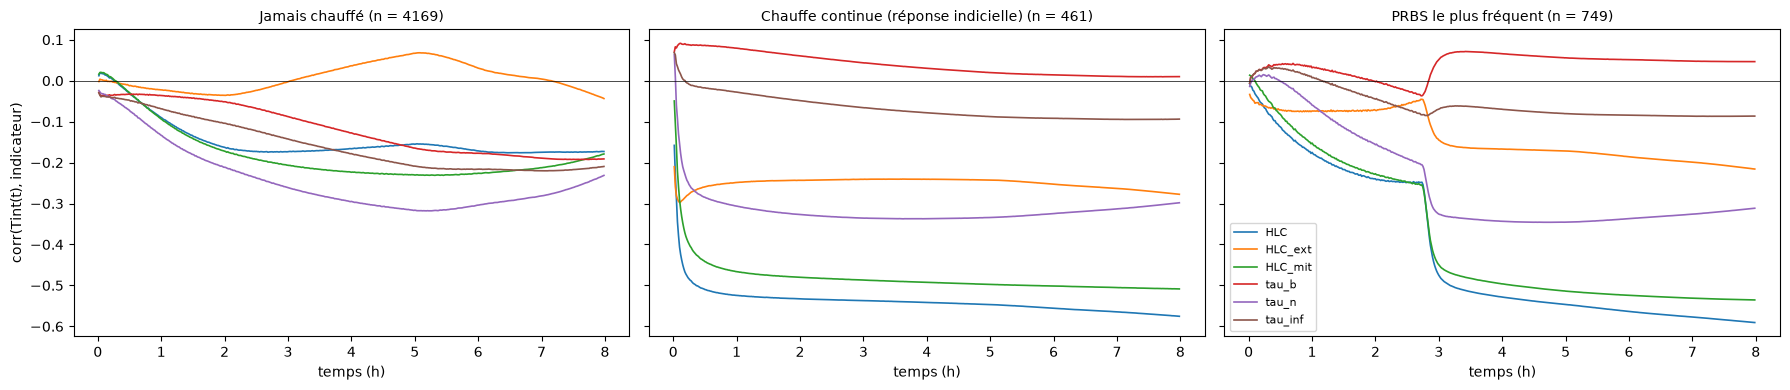

In [13]:
timelines = {}
for name, g in chosen.items():
    m = group == g
    plot_group_responses(eda.x[m, :, 0], eda.y[m], name)
    timelines[f"{name} (n = {int(m.sum())})"] = information_timeline(eda.x[m, :, 0], eda.y[m])
plot_information_timelines(timelines);

In [14]:
# corrélation entre Tint(t) et chaque indicateur à 1 h, 4 h et 8 h
pd.concat({name: df.iloc[[59, 239, 479]] for name, df in timelines.items()}, names=["groupe"]).round(2)

HLC  HLC_ext  \
groupe                                          temps (h)                  
Jamais chauffé (n = 4169)                       0.983     -0.09    -0.02   
                                                3.983     -0.17     0.04   
                                                7.983     -0.17    -0.04   
Chauffe continue (réponse indicielle) (n = 461) 0.983     -0.52    -0.25   
                                                3.983     -0.54    -0.24   
                                                7.983     -0.58    -0.28   
PRBS le plus fréquent (n = 749)                 0.983     -0.18    -0.08   
                                                3.983     -0.53    -0.17   
                                                7.983     -0.59    -0.22   

                                                           HLC_mit  tau_b  \
groupe                                          temps (h)                   
Jamais chauffé (n = 4169)                       0.983        -0.09  -0.04   
                                                3.983        -0.22  -0.13   
                                                7.983        -0.18  -0.19   
Chauffe continue (réponse indicielle) (n = 461) 0.983        -0.47   0.08   
                                                3.983        -0.49   0.03   
                                                7.983        -0.51   0.01   
PRBS le plus fréquent (n = 749)                 0.983        -0.15   0.04   
                                                3.983        -0.50   0.07   
                                                7.983        -0.54   0.05   

                                                           tau_n  tau_inf  
groupe                                          temps (h)                  
Jamais chauffé (n = 4169)                       0.983      -0.13    -0.07  
                                                3.983      -0.30    -0.18  
                                                7.983      -0.23    -0.21  
Chauffe continue (réponse indicielle) (n = 461) 0.983      -0.31    -0.03  
                                                3.983      -0.34    -0.08  
                                                7.983      -0.30    -0.09  
PRBS le plus fréquent (n = 749)                 0.983      -0.06     0.01  
                                                3.983      -0.34    -0.07  
                                                7.983      -0.31    -0.09

**Lecture.** Les plus grands groupes sont surtout des **échelons retardés** (chauffage éteint, puis allumé jusqu'à la fin). Sur les figures, les courbes sont colorées par HLC, et les profils donnent, minute par minute, la corrélation entre $T_{int}(t)$ et chaque indicateur.
- **L'information arrive avec la chauffe.** Dans le groupe PRBS (allumage à 2,75 h), la corrélation avec le HLC reste faible (≈ −0,25) tant que le chauffage est éteint, puis **saute à ≈ −0,5 dans les minutes qui suivent l'allumage**. En chauffe continue, ce niveau est atteint en une demi-heure puis progresse lentement (−0,58 à 8 h). Sans chauffe, elle plafonne à −0,17.
- **Capacité et déperdition se compensent.** En chauffe continue, $\tau_b$ est presque décorrélée de $T_{int}(t)$ à tout instant (|corr| < 0,1), bien qu'anti-corrélée au HLC (−0,68). Une forte inertie ralentit l'échauffement, mais va de pair avec un HLC plus faible qui l'augmente : **les deux effets s'annulent sur l'amplitude**. Seule la **forme** de la réponse les sépare : c'est le problème classique d'identifiabilité des modèles RC sur fenêtre courte.
- **$\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$ ont des profils de même forme**, proportionnels à leur part de variance : un instant isolé ne renseigne que sur la somme.

#### b) Ce que capte un modèle linéaire

Régression ridge de la séquence brute ($T_{int}$ et $U$ sur les $h$ premières heures) vers les six indicateurs, ajustée sur les fichiers d'entraînement de l'échantillon et évaluée sur ceux de validation ($\log\tau$ en sortie, $R^2$ en unités physiques).

In [15]:
split_eda = SplitSpec()
tr = torch.isin(eda.batch_id, torch.tensor(split_eda.train))
va = torch.isin(eda.batch_id, torch.tensor(split_eda.val))
hours = (0.5, 1, 2, 4, 6, 8)

ridge_all = ridge_information_curve(eda.x[tr], eda.y[tr], eda.x[va], eda.y[va], hours=hours)
ridge_all

,alpha,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
fenêtre (h),,,,,,,
0.5,0.00,0.046,0.005,0.042,-0.012,0.010,-0.016
1.0,0.00,0.076,0.010,0.065,-0.012,0.030,-0.015
2.0,0.00,0.147,0.021,0.129,-0.014,0.052,-0.017
4.0,0.01,0.220,0.035,0.192,-0.014,0.084,-0.015
6.0,0.10,0.240,0.040,0.207,-0.013,0.088,-0.011
8.0,0.10,0.258,0.053,0.214,-0.013,0.088,-0.011


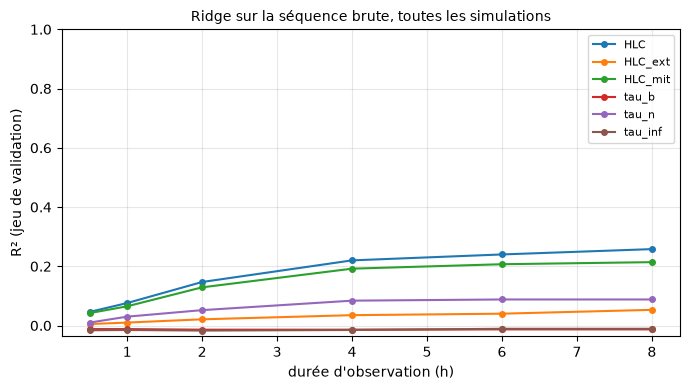

In [16]:
plot_information_curve(ridge_all, "Ridge sur la séquence brute, toutes les simulations");

In [17]:
# même régression à excitation fixée : à l'intérieur de chaque groupe, découpage aléatoire 75/25
gen = torch.Generator().manual_seed(SEED)
ridge_groups = {}
for name, g in chosen.items():
    idx = torch.nonzero(group == g).squeeze(1)
    idx = idx[torch.randperm(idx.numel(), generator=gen)]
    cut = int(0.75 * idx.numel())
    a, b = idx[:cut], idx[cut:]
    ridge_groups[name] = ridge_information_curve(eda.x[a], eda.y[a], eda.x[b], eda.y[b], hours=(1, 2, 4, 8))
pd.concat(ridge_groups, names=["groupe"])

alpha    HLC  HLC_ext  \
groupe                                fenêtre (h)                          
Jamais chauffé                        1            0.010  0.031   -0.005   
                                      2            0.010  0.042   -0.001   
                                      4            0.001  0.110    0.323   
                                      8            0.001  0.179    0.427   
Chauffe continue (réponse indicielle) 1            0.100  0.342    0.115   
                                      2            0.100  0.356    0.120   
                                      4            0.000  0.408    0.289   
                                      8            0.000  0.495    0.500   
PRBS le plus fréquent                 1            1.000  0.039   -0.015   
                                      2            1.000  0.049   -0.015   
                                      4            0.001  0.353    0.299   
                                      8            0.001  0.425    0.451   

                                                   HLC_mit  tau_b  tau_n  \
groupe                                fenêtre (h)                          
Jamais chauffé                        1              0.042 -0.005  0.070   
                                      2              0.051  0.003  0.085   
                                      4              0.069  0.106  0.160   
                                      8              0.121  0.140  0.182   
Chauffe continue (réponse indicielle) 1              0.235  0.009 -0.014   
                                      2              0.241  0.018 -0.000   
                                      4              0.106  0.022  0.057   
                                      8              0.229  0.107  0.186   
PRBS le plus fréquent                 1              0.017 -0.015  0.016   
                                      2              0.027 -0.005  0.081   
                                      4              0.204  0.090  0.208   
                                      8              0.211  0.100  0.215   

                                                   tau_inf  
groupe                                fenêtre (h)           
Jamais chauffé                        1              0.002  
                                      2              0.012  
                                      4              0.082  
                                      8              0.095  
Chauffe continue (réponse indicielle) 1             -0.018  
                                      2             -0.002  
                                      4              0.021  
                                      8              0.082  
PRBS le plus fréquent                 1             -0.015  
                                      2              0.005  
                                      4              0.068  
                                      8              0.074

**Lecture.**
- **Toutes excitations confondues, le linéaire échoue** : à 8 h, $R^2$ = 0,26 sur le HLC, 0,05 sur $\mathrm{HLC}_{ext}$, ≈ 0 sur $\tau_b$ et $\tau_\infty$. Un modèle linéaire affecte un poids fixe à chaque minute ; or la minute informative (l'allumage) change d'une excitation à l'autre.
- **À excitation fixée, le même modèle fait deux fois mieux** : 0,43 à 0,50 sur le HLC, 0,45 à 0,50 sur $\mathrm{HLC}_{ext}$. L'information est donc présente ; c'est le **mélange des excitations** qui la rend inaccessible au linéaire. Il faut un modèle non linéaire qui lise $T_{int}$ **conditionnellement à** $U$.
- **$\mathrm{HLC}_{ext}$ a sa propre signature** : à excitation fixée, il est mieux prédit que $\mathrm{HLC}_{mit}$ (0,45–0,50 contre 0,21–0,23), et même sans chauffe (0,43 contre 0,18 pour le HLC). L'information sur la répartition est dans la forme de la courbe.
- **Les $\tau$ restent difficiles** ($R^2 \le 0{,}2$), comme prévu en section 1.

Ces groupes comptent 461 à 4 169 simulations pour 480 variables : ces $R^2$ sont des ordres de grandeur (±0,1).

#### c) ACP des réponses en température

Sur toutes les simulations (variabilité de l'excitation **et** du bâtiment), puis en chauffe continue (bâtiment seul).

Composantes pour 99 % de variance : 12


Composantes pour 99 % de variance : 2


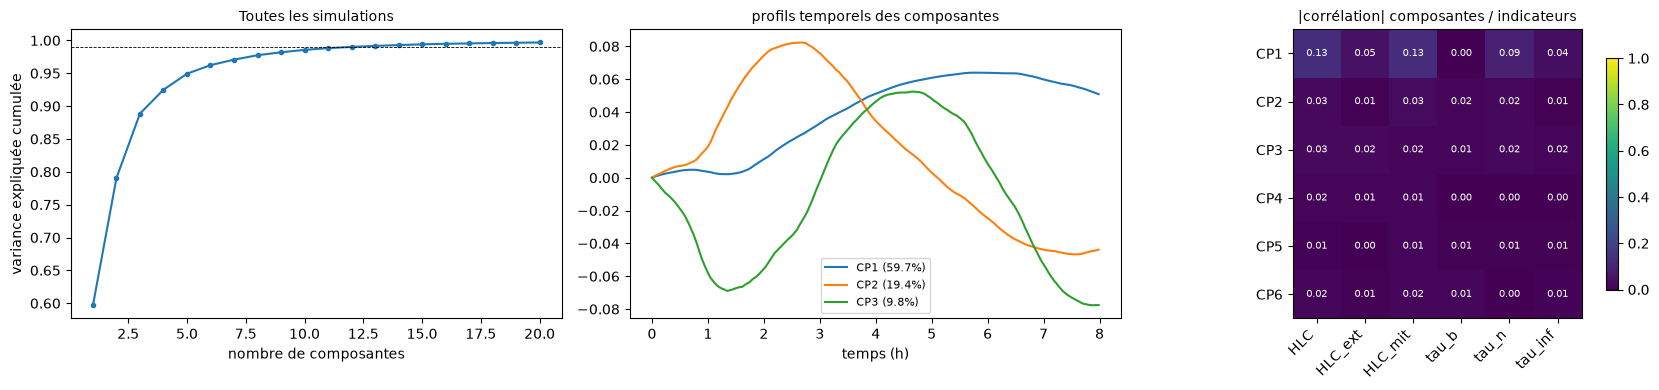

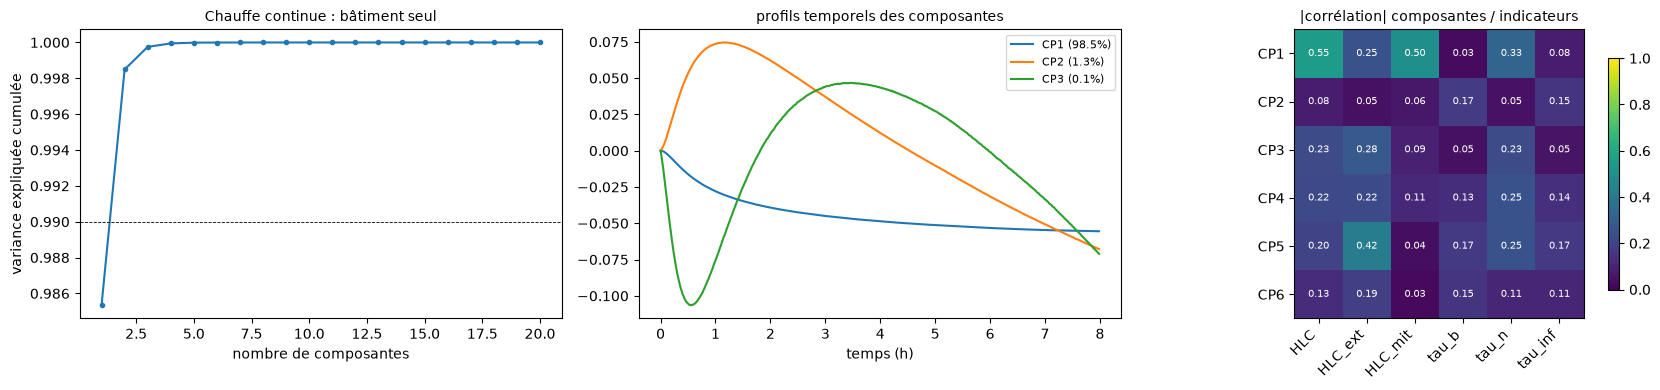

In [18]:
res_all = pca(eda.x[:20_000, :, 0], k=20)
plot_pca(res_all, eda.y[:20_000], "Toutes les simulations")
print("Composantes pour 99 % de variance :", int((res_all.explained.cumsum(0) < 0.99).sum()) + 1)
m_step = group == chosen["Chauffe continue (réponse indicielle)"]
res_step = pca(eda.x[m_step, :, 0], k=20)
plot_pca(res_step, eda.y[m_step], "Chauffe continue : bâtiment seul")
print("Composantes pour 99 % de variance :", int((res_step.explained.cumsum(0) < 0.99).sum()) + 1)

**Lecture.**
- **Toutes simulations confondues, la variance des courbes est celle de l'excitation** : 12 composantes pour 99 %, qui décrivent *quand* la chauffe a lieu, et aucune n'est corrélée à plus de 0,13 avec un indicateur.
- **À excitation fixée, l'effet du bâtiment est de très petite dimension** : une composante explique 98,5 % de la variance et trois 99,97 %. La première est l'amplitude de la montée, liée au HLC (|corr| = 0,55).
- **L'information fine est dans des composantes négligeables en variance** : $\mathrm{HLC}_{ext}$ est lié à CP3 et CP5 (|corr| = 0,28 et 0,42), qui pèsent ensemble moins de 0,1 % de la variance. Il ne faut donc **pas compresser les entrées par ACP**, et l'on s'attend à ce que $\mathrm{HLC}_{ext}$ et les $\tau$ soient **fragiles au bruit de mesure**.

### 3.7 Un problème inverse mal posé

Un problème inverse est **bien posé** au sens de Hadamard s'il admet une solution (existence), une seule (unicité), et si celle-ci dépend continûment des données (stabilité). Ici, le simulateur $S : (\theta, z, u) \mapsto T_{int}$ associe une courbe au bâtiment $\theta$ (qui détermine $y$), à l'état initial des parois $z$ et à l'excitation $u$ ; apprendre $x \mapsto y$ revient à inverser $S$. Les trois conditions sont en défaut :

| Condition | Propriété de $S$ requise | Ce que montrent les données |
|---|---|---|
| Unicité | **injectivité** : deux bâtiments différents donnent deux courbes différentes | des « jumelles » : courbes quasi identiques, HLC très différents (ci-dessous) |
| Existence | **surjectivité** sur les mesures : toute mesure est une sortie possible de $S$ | les courbes simulées occupent une variété de dimension ≈ 3 (3.6 c) et un nombre fini d'excitations (3.6 a) |
| Stabilité | une petite erreur de mesure change peu l'estimation | l'information fine pèse < 0,1 % de la variance (3.6 c) ; vérifié en 6.5 |

**Unicité.** À excitation fixée, on associe à chaque maison $i$ sa plus proche voisine $v(i)$, celle dont la courbe $T_{int}$ est la plus proche (écart quadratique moyen sur 480 minutes). On appelle **jumelles** deux voisines à moins de 0,05 °C, l'ordre de grandeur du bruit d'un capteur. Si deux voisines avaient exactement la même courbe, $\overline{(y_i - y_{v(i)})^2}/2$ mesurerait la variance de $y$ que la courbe ne détermine pas. C'est le **test Delta** (Pi & Peterson, 1994) :
$$R^2_\Delta = 1 - \frac{\overline{(y_i - y_{v(i)})^2}}{2\,\mathrm{Var}(y)}.$$
Les voisines étant choisies sur la ressemblance **globale** des courbes, $R^2_\Delta$ est la part de variance expliquée par cette seule ressemblance. Un modèle qui exploite les détails de forme peut faire mieux.

In [19]:
group_curves = {name: (eda.x[group == g, :, 0], eda.y[group == g]) for name, g in chosen.items()}
ill_posedness_table(group_curves, threshold=0.05).T.round(3)

,Jamais chauffé,Chauffe continue (réponse indicielle),PRBS le plus fréquent
n,4169.000,461.000,749.000
"distance au plus proche voisin, médiane (°C)",0.012,0.068,0.064
part de maisons ayant une jumelle < 0.05 °C (%),99.760,24.078,19.626
|ΔHLC| médian entre jumelles (W/K),28.480,25.071,25.678
|ΔHLC| médian entre maisons au hasard (W/K),29.724,29.171,28.109
R² test Delta HLC,0.107,0.401,0.350
R² test Delta HLC_ext,0.287,0.203,0.137
R² test Delta HLC_mit,0.076,0.277,0.267
R² test Delta tau_b,0.112,0.125,0.064
R² test Delta tau_n,0.149,0.231,0.146


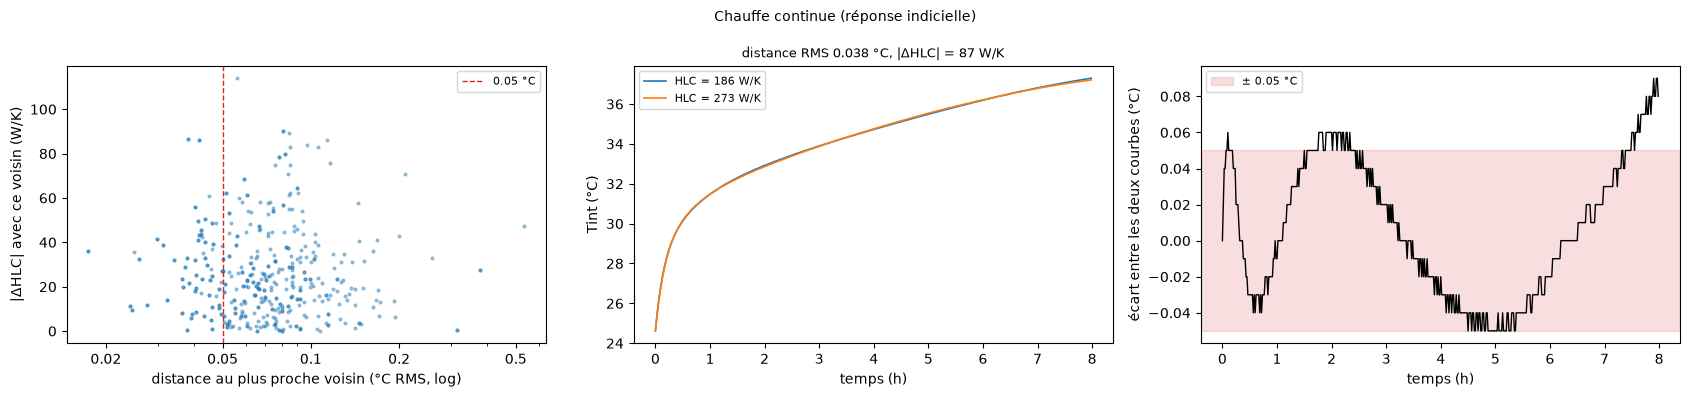

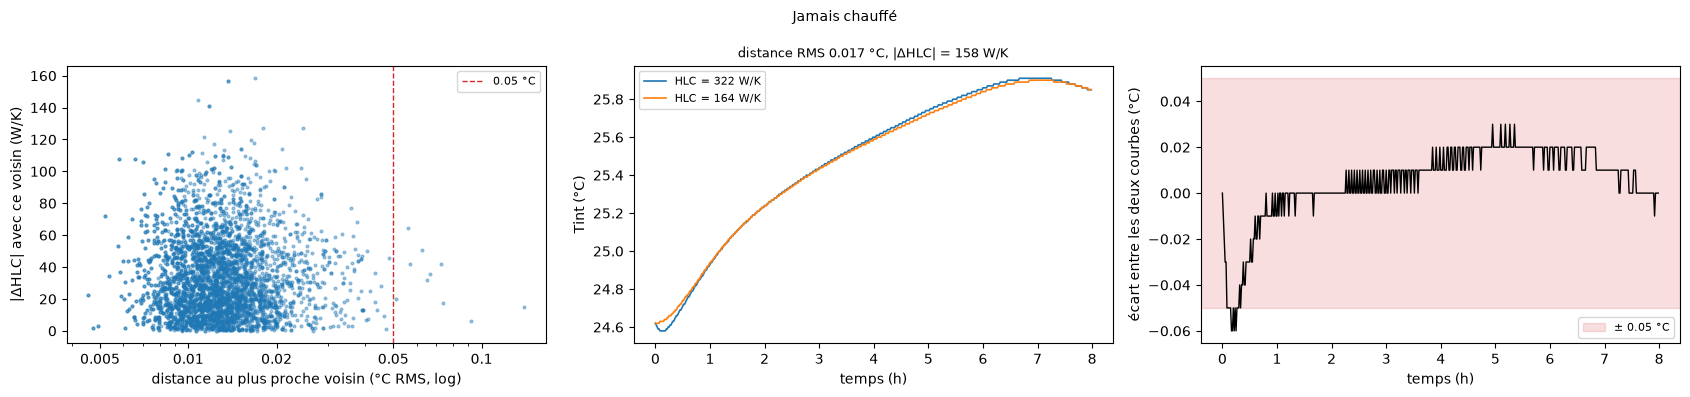

In [20]:
for name in ("Chauffe continue (réponse indicielle)", "Jamais chauffé"):
    plot_twins(*group_curves[name], title=name, threshold=0.05)

**Lecture.**
- **Sans chauffe, l'injectivité est presque perdue.** 99,8 % des maisons ont une jumelle, à 0,012 °C en médiane, soit à peu près le pas d'arrondi des données. Leurs HLC diffèrent de 28 W/K en médiane, contre 30 W/K entre deux maisons prises au hasard. Exemple : deux maisons à 164 et 322 W/K dont les courbes ne s'écartent jamais de plus de 0,06 °C. $R^2_\Delta$ = 0,11 sur le HLC.
- **Avec chauffe, les courbes se distinguent davantage** : 0,06 à 0,07 °C entre voisines en médiane, 20 à 24 % de jumelles, et $R^2_\Delta$ = 0,35 à 0,40 sur le HLC. Il reste pourtant des jumelles très différentes : 186 et 273 W/K en chauffe continue, à 0,04 °C l'une de l'autre.
- **Le modèle dépasse $R^2_\Delta$** : en validation, 0,24 sans chauffe et 0,49 en chauffe continue sur le HLC, 0,53 contre 0,20 sur $\mathrm{HLC}_{ext}$ (6.6 c). Il exploite les composantes de forme de très faible variance (3.6 c), que la distance globale ignore. Mais ces écarts sont de quelques centièmes de degré, l'ordre du bruit d'un capteur : c'est là que le problème devient **instable**. Entraîné avec bruit, le modèle redescend sans chauffe à 0,16, près de $R^2_\Delta$.

**Bilan.** La courbe ne détermine pas le bâtiment, et ce qu'elle en dit au-delà de sa forme globale se joue à l'échelle du bruit. Deux causes physiques, vues en 3.6 : la compensation entre capacité et déperdition, et l'état initial des parois, inconnu.

**Existence.** À excitation fixée, trois composantes décrivent 99,97 % des réponses (3.6 c) : les courbes simulées forment une variété de dimension ≈ 3 dans un espace de dimension 480. Une mesure réelle, bruitée d'environ 0,05 °C à chaque minute, s'en écarte presque sûrement : elle n'a pas d'antécédent exact par $S$. De même, le modèle n'apprend que les excitations du jeu (3.6 a), avec une seule météo et une seule typologie de bâtiment.

**Stabilité.** Inverser $S$ revient à amplifier des composantes de très faible variance, donc le bruit qui s'y superpose. La section 6.5 le vérifie : entraîné sans bruit, le modèle voit son $R^2$ sur le HLC passer de 0,42 à 0,26 avec seulement 0,02 °C de bruit.

**Conséquences pour la modélisation** (les remèdes classiques aux problèmes mal posés) :
- **non-unicité** → prédire une **loi** $p(y \mid x)$, ici une moyenne et une variance par indicateur, plutôt qu'une valeur (5.3). L'objectif n'est pas $R^2 = 1$, mais une incertitude honnête ;
- **instabilité** → régulariser : entraîner avec du bruit de mesure, ce qui équivaut à une régularisation de Tikhonov (Bishop, 1995) (6.5) ;
- **existence limitée** → ne revendiquer la performance que sur le domaine simulé : nouveaux bâtiments, excitations et météo connues (7.6).

### 3.8 Synthèse de l'EDA

| Constat | Conséquence pour le modèle |
|---|---|
| $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ et $\tau_n \le \tau_\infty \le \tau_b$ dans 100 % des cas | tête qui garantit ces relations par construction (5.2) |
| Cibles positives, $\tau$ asymétriques, échelles différentes | sorties log-normales, perte sur des cibles standardisées ($\log\tau$), même poids par famille |
| L'information arrive avec la chauffe ; le linéaire échoue toutes excitations confondues | modèle non linéaire lisant $T_{int}$ conditionnellement à $U$ (CNN + GRU) |
| Capacité et déperdition se compensent sur l'amplitude ; $\mathrm{HLC}_{ext}$ dans des composantes < 0,1 % de variance | lire toute la courbe, sans ACP ; dérivée $\mathrm{d}T_{int}/\mathrm{d}t$ en entrée |
| Problème mal posé : jumelles aux HLC très différents | sortie probabiliste, intervalles calibrés |
| Information fine fragile au bruit | entraînement avec bruit capteur |
| 8,4 % sans chauffe ; information dépendant de l'excitation | métriques par sous-groupe d'excitation (7.3) |
| Fichiers i.i.d. ; excitations partagées entre fichiers | découpage par fichier ; le test porte sur de nouveaux bâtiments, pas de nouvelles excitations |

## 4. Protocole d'évaluation

**Découpage par fichier** : 14 fichiers pour l'entraînement (700 000 simulations), 3 pour la validation (choix des variantes, arrêt précoce), 3 pour le test, évalués **une seule fois**, à la fin, sur le modèle retenu.

In [21]:
split = SplitSpec()
print("train :", [files[i].name for i in split.train])
print("val   :", [files[i].name for i in split.val])
print("test  :", [files[i].name for i in split.test])

train : ['batch_1.pt', 'batch_2.pt', 'batch_3.pt', 'batch_4.pt', 'batch_5.pt', 'batch_6.pt', 'batch_7.pt', 'batch_8.pt', 'batch_9.pt', 'batch_10.pt', 'batch_11.pt', 'batch_12.pt', 'batch_13.pt', 'batch_14.pt']
val   : ['batch_15.pt', 'batch_16.pt', 'batch_17.pt']
test  : ['batch_18.pt', 'batch_19.pt', 'batch_20.pt']


**Normalisation** (`hlcnet.data.Normalizer`, ajustée sur l'entraînement seul) : standardisation par canal des entrées ; $\log$ des trois $\tau$ puis standardisation des cibles. Les métriques sont calculées en unités physiques (W/K, h).

**Métriques, par indicateur et par famille** (HLC, $H_b$, CDT) : RMSE, MAE, erreur relative moyenne (MAPE), $R^2$, et les 95ᵉ et 99ᵉ percentiles et le maximum de l'erreur absolue. Le P95 est le critère de l'article ; le P99 et le maximum révèlent les grandes erreurs rares, auxquelles il est aveugle. S'y ajoutent :
- le **respect des contraintes physiques** par les prédictions ;
- la **calibration** des intervalles (couverture observée contre niveau nominal) ;
- la **robustesse au bruit** de mesure ;
- les erreurs **par sous-groupe d'excitation**.

## 5. Modèle

### 5.1 Cadre : inférence amortie à partir de simulations

Le problème est un problème inverse mal posé (3.7) : on ne cherche pas une valeur unique, mais la loi des indicateurs sachant la courbe. C'est le cadre de l'**inférence fondée sur la simulation** (Cranmer *et al.*, 2020) dans sa version **amortie** : un réseau est entraîné une fois sur des couples simulés $(x, y)$, puis s'applique instantanément à toute nouvelle mesure, comme dans la phase 2 de l'article. Notre modèle est une **estimation neuronale gaussienne de la loi a posteriori** (Papamakarios & Murray, 2016) : un encodeur résume la série, une tête prédit une moyenne et une variance par indicateur, et la couverture des intervalles vérifie la calibration (Talts *et al.*, 2018).

Sources d'inspiration hors bâtiment, même schéma (réponse courte à une excitation connue, paramètres cachés, apprentissage sur simulations) : TCN-LSTM pour l'état de santé des batteries, dynoNet en identification de systèmes (Forgione & Piga, 2021), et ROCKET, meilleure méthode du banc d'essai de régression de séries temporelles (Tan *et al.*, 2021), qui sert de référence. Côté bâtiment, Baasch *et al.* (2021) concluent à l'intérêt de l'apprentissage profond pour identifier le HLC.

### 5.2 Architecture : CNN-GRU à sorties physiquement contraintes

Chaque bloc répond à un constat de l'EDA :

| Bloc | Justification |
|---|---|
| Entrées $[T_{int},\ \mathrm{d}T_{int}/\mathrm{d}t,\ U]$ | lire $T_{int}$ conditionnellement à $U$ (3.6 b) ; la dérivée rend visibles les réactions juste après les commutations (3.6 a) |
| 3 convolutions (noyaux 7, 5, 5 dilaté), un seul sous-échantillonnage (480 → 240) | motifs locaux de 7 à 25 min, sans compression précoce : l'information sur $\mathrm{HLC}_{ext}$ tient dans de petits détails de forme (3.6 c) |
| GRU bidirectionnel, 2 couches | forme globale sur 8 h, seule à séparer capacité et déperdition (3.6 a) ; la série complète est connue à l'inférence |
| *Pooling* par attention + moyenne | pondérer les instants informatifs, qui suivent l'allumage (3.6 a) |
| Tête physique | contraintes garanties (2, 3.8) |
| Tête d'incertitude | une variance par indicateur (3.7) |

**Tête physique.** Chaque grandeur positive est paramétrée par $q = \exp(\mu_q + s_q a_q)$, où $a_q$ est la sortie du réseau et $(\mu_q, s_q)$ la moyenne et l'écart-type de $\log q$ à l'entraînement : le modèle part du bâtiment typique et apprend des écarts. On prédit le HLC et la part $r \in\ ]0, 1[$ des déperditions vers l'extérieur (sigmoïde) :
$$\mathrm{HLC}_{ext} = r\,\mathrm{HLC}, \quad \mathrm{HLC}_{mit} = (1-r)\,\mathrm{HLC}, \quad \tau_\infty = \tau_n + e^{(\cdot)}, \quad \tau_b = \tau_\infty + e^{(\cdot)}.$$
**Toute** prédiction respecte ainsi les contraintes, même loin des simulations (testé avec des poids aléatoires). Ablations : tête `sum` (prédire $\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$, sommer) et tête `free` (six sorties libres).

210 000 paramètres ; 16 s par époque sur 140 000 simulations (GPU T4).

### 5.3 Perte : vraisemblance gaussienne hétéroscédastique

Pour chaque indicateur (standardisé, $\log\tau$), le modèle prédit $\mu(x)$ et $\sigma^2(x)$ et minimise
$$\mathcal{L} = \tfrac12 \log \sigma^2(x) + \frac{(y - \mu(x))^2}{2\,\sigma^2(x)}.$$
C'est l'analogue des moindres carrés généralisés réalisables (FGLS), avec des poids $1/\sigma^2$ appris et dépendant de l'entrée ; le terme $\tfrac12\log\sigma^2$ empêche de se déclarer incertain sans contrepartie. La variante **$\beta$-NLL** (Seitzer *et al.*, 2022, $\beta = 0{,}5$) évite que la moyenne abandonne les exemples difficiles en gonflant leur variance. Les trois familles ont le même poids total ; les deux premières époques utilisent l'erreur quadratique seule.

### 5.4 Entraînement

AdamW ($2\cdot10^{-3}$, *weight decay* $10^{-4}$), montée linéaire puis décroissance cosinus, écrêtage du gradient, précision mixte (tête en float32), arrêt précoce sur l'erreur quadratique pondérée de validation, un critère indépendant de la perte pour comparer équitablement les variantes. Chaque expérience est décrite par un YAML (`configs/`), entraînée par `scripts/train.py` sur GPU Kaggle (`notebooks/kaggle_train.ipynb`) et sauvegardée avec son normaliseur (`artifacts/runs/<nom>/`).

### 5.5 Références de comparaison

- **Ridge** sur la série brute (3.6 b) et **ROCKET + ridge** (Dempster *et al.*, 2020 ; 2 000 noyaux aléatoires) ;
- **MLP** avec la même tête : apport de l'architecture séquentielle ;
- **Encodeurs alternatifs**, même tête, même perte, même entraînement :
  - TCN-GRU (convolutions dilatées 1 à 32, champ récepteur ≈ 8 h, inspiré des TCN-LSTM pour batteries) ;
  - TCN seul ;
  - FiLM-GRU, où $U$ **module** les caractéristiques de $T_{int}$ (Perez *et al.*, 2018).

## 6. Résultats sur la validation

Sauf mention contraire, toutes les variantes sont entraînées sur les **mêmes 140 000 simulations** et évaluées sur les **mêmes 15 000 simulations de validation**.

### 6.1 Comparaison des variantes ($R^2$)

In [22]:
table = comparison_table(RUNS)
try:  # référence linéaire de la section 3.6 b (8 h d'observation)
    table.loc["ridge sur la série brute (3.6 b)"] = {**ridge_all.loc[8.0, list(TARGET_NAMES)].to_dict()}
except NameError:
    pass
table.round(3)

,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf,violations HLC = ext + mit (%),simulations d'entraînement
CNN-GRU (référence),0.413,0.418,0.264,0.101,0.236,0.073,0.00,140000.0
tête « sum » (ext + mit),0.415,0.423,0.268,0.101,0.237,0.073,0.00,140000.0
tête libre (sans contrainte),0.414,0.418,0.266,0.102,0.237,0.075,97.52,140000.0
sans canal dérivée,0.399,0.365,0.261,0.088,0.221,0.065,0.00,140000.0
perte MSE (sans incertitude),0.415,0.423,0.266,0.105,0.238,0.076,0.00,140000.0
"entraîné avec bruit 0,25 °C",0.306,0.091,0.231,0.012,0.124,0.009,0.00,140000.0
TCN-GRU,0.394,0.392,0.257,0.103,0.228,0.080,0.00,140000.0
TCN (sans GRU),0.414,0.430,0.268,0.104,0.238,0.075,0.00,140000.0
FiLM-GRU,0.413,0.431,0.266,0.103,0.240,0.077,0.00,140000.0
MLP (non séquentiel),0.301,0.084,0.230,0.001,0.128,0.004,0.00,140000.0


**Lecture.**
1. **Le séquentiel est décisif.** Avec la même tête, le MLP plafonne à 0,30 sur le HLC et 0,08 sur $\mathrm{HLC}_{ext}$ ; le CNN-GRU atteint 0,41 et 0,42.
2. **ROCKET est nettement dépassé** (0,34 et 0,16) : les filtres aléatoires captent la forme grossière, pas la dynamique fine.
3. **Les bonnes architectures convergent** : CNN-GRU, TCN et FiLM-GRU, de 210 000 à 508 000 paramètres, sont à 0,41 sur le HLC et 0,42–0,43 sur $\mathrm{HLC}_{ext}$, à 0,01 près (le TCN-GRU, arrêté à l'époque 17, est un peu en dessous). Quand des modèles aussi différents s'accordent, la limite est dans les données (6.2, 6.6).
4. **Ablations** : la dérivée aide sur données propres (+0,05 sur $\mathrm{HLC}_{ext}$) ; la $\beta$-NLL ne coûte rien face à la MSE et fournit des intervalles ; les têtes `share` et `sum` sont équivalentes.
5. **Choix : CNN-GRU**, 2,5 à 4 fois plus rapide que TCN et FiLM-GRU pour la même précision.

### 6.2 Cinq fois plus de données

Le CNN-GRU est ré-entraîné sur les 700 000 simulations d'entraînement et évalué sur 30 000 simulations de validation.

In [23]:
final_runs = {"cnn_gru_share_nll": "CNN-GRU, 140 000 simulations", "final_700k": "CNN-GRU, 700 000 simulations"}
comparison_table(RUNS, final_runs).round(3)

,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf,violations HLC = ext + mit (%),simulations d'entraînement
"CNN-GRU, 140 000 simulations",0.413,0.418,0.264,0.101,0.236,0.073,0.0,140000.0
"CNN-GRU, 700 000 simulations",0.416,0.442,0.267,0.116,0.239,0.084,0.0,700000.0


**Lecture.** ×5 données : +0,003 sur le HLC, +0,02 sur $\mathrm{HLC}_{ext}$. Ce n'est pas la quantité de données qui limite, mais l'information par essai (3.7).

### 6.3 Contraintes physiques : gratuites et nécessaires

In [24]:
pd.DataFrame(
    {label: load_metrics(RUNS / name)["constraints"] for name, label in
     [("cnn_gru_share_nll", "tête share (contrainte)"), ("abl_head_free", "tête libre"), ("rocket_ridge", "ROCKET + ridge (linéaire)")]}
).T

,part |HLC - (ext + mit)| > tol,écart moyen HLC - (ext + mit) (W/K),part ordre tau violé,part valeurs négatives
tête share (contrainte),0.000,9.857e-07,0.0,0.0
tête libre,0.975,2.897e-02,0.0,0.0
ROCKET + ridge (linéaire),0.000,4.434e-06,0.0,0.0


**Lecture.** La tête libre a la même précision, mais **97,5 % de ses prédictions violent** $\mathrm{HLC} = \mathrm{HLC}_{ext} + \mathrm{HLC}_{mit}$ (écart moyen 0,03 W/K). Faible ici, rien ne le borne sur un bâtiment réel éloigné des simulations, et un rapport incohérent ruinerait le diagnostic. La tête contrainte : 0 %, sans coût. ROCKET + ridge respecte aussi la relation : un modèle **linéaire** hérite de toute relation linéaire de ses cibles d'entraînement.

### 6.4 Incertitude : calibration, finesse, biais

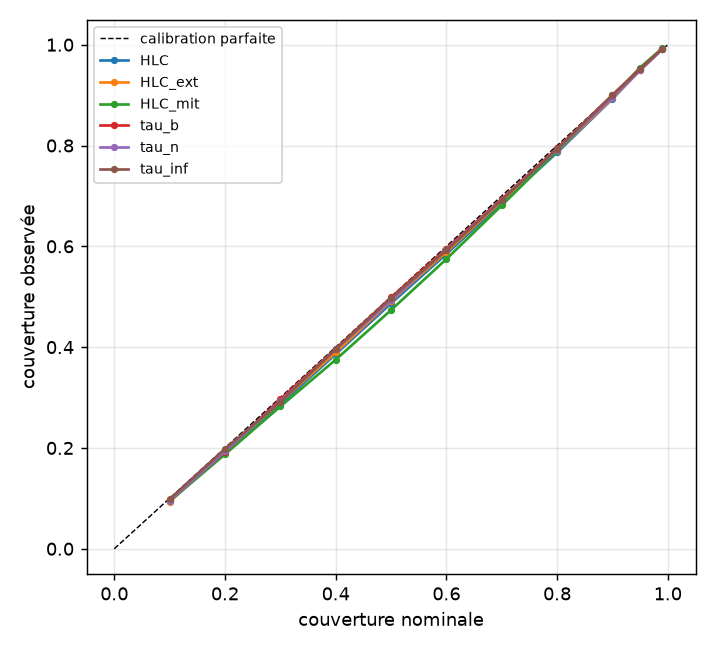

,largeur médiane de l'intervalle à 95 %
HLC,92.5
HLC_ext,49.5
HLC_mit,88.5
tau_b,36.1
tau_n,6.6
tau_inf,27.2


In [25]:
EVAL_VAL = ARTIFACTS / "eval" / "val"
display(Image(filename=str(EVAL_VAL / "reliability.png"), width=420))
read_table(EVAL_VAL / "interval_width_95.csv").rename(columns={"0": "largeur médiane de l'intervalle à 95 %"}).round(1)

In [26]:
read_table(EVAL_VAL / "retransformation_bias.csv").round(3)

,biais médiane exp(mu),biais moyenne exp(mu + s²/2),rmse médiane,rmse moyenne
indicateur,,,,
tau_b,-0.931,-0.094,9.441,9.398
tau_n,-0.145,-0.018,1.728,1.722
tau_inf,-0.822,-0.068,7.126,7.081


**Lecture** (modèle de référence, validation).
- **Calibration** : le diagramme de fiabilité suit la diagonale de 10 % à 99 % pour les six indicateurs.
- **Finesse** : les intervalles à 95 % restent larges (92 W/K sur le HLC, soit ±46 W/K ; ±3,3 h sur $\tau_n$). Ils mesurent l'incertitude irréductible de 3.7 : le modèle est calibré, et sa finesse est bornée par l'essai.
- **Biais de retransformation** : $\exp(\mu)$ est la **médiane** d'une loi log-normale, inférieure à sa moyenne, d'où −0,9 h sur $\tau_b$. Le modèle prédisant $s^2$, on corrige par $\mathbb{E}[\tau] = \exp(\mu + s^2/2)$ : biais réduit d'environ 90 %, RMSE légèrement plus faible.

### 6.5 Robustesse au bruit et choix du modèle final

On ajoute à $T_{int}$ un bruit gaussien indépendant à chaque minute, puis on arrondit à 0,01 °C.

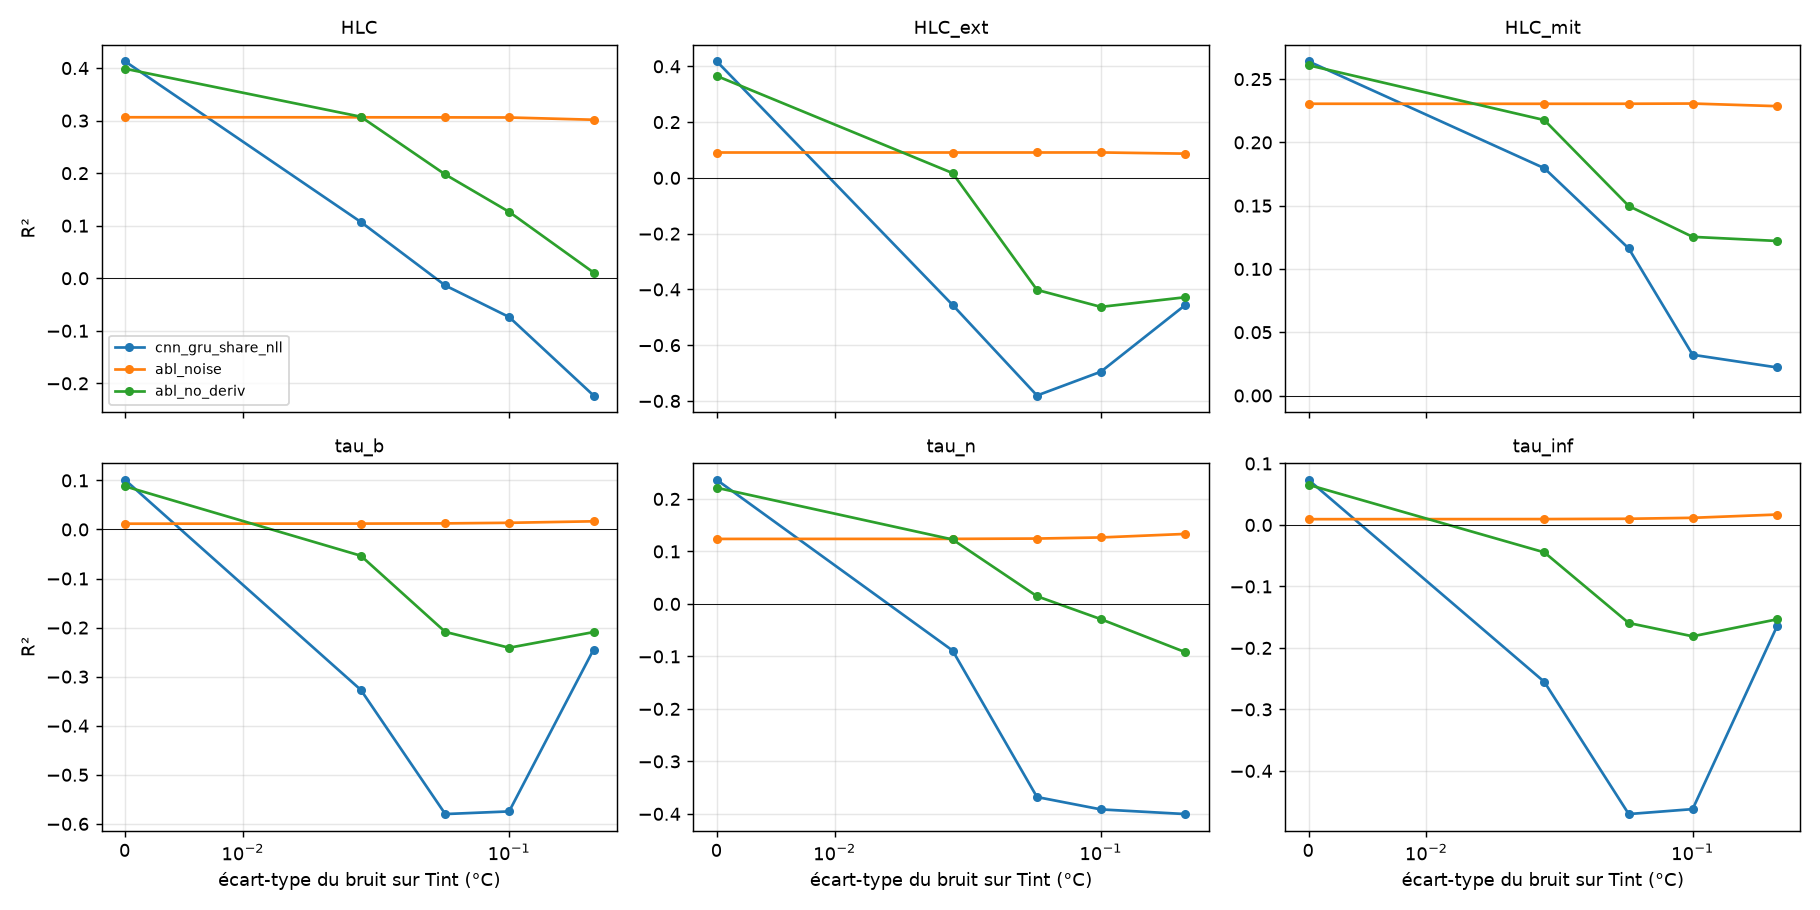

In [27]:
display(Image(filename=str(EVAL_VAL / "noise_robustness.png"), width=900))

**Lecture** (modèles 140 000 simulations).
- **Entraîné sans bruit, le modèle s'effondre** : à 0,02 °C, le $R^2$ du HLC chute de 0,41 à 0,11 et ceux de $\mathrm{HLC}_{ext}$ et des $\tau$ deviennent **négatifs**. C'est l'instabilité annoncée en 3.7.
- **La dérivée amplifie le bruit** (dériver un bruit indépendant double sa variance) : sans dérivée, 0,31 à 0,02 °C.
- **Entraîné avec 0,25 °C, il est stable**, mais renonce à $\mathrm{HLC}_{ext}$ (0,09) et aux $\tau$.

On compare donc deux modèles entraînés sur 700 000 simulations, sans bruit et avec 0,05 °C :

In [28]:
EVAL_FINAL = ARTIFACTS / "eval_final" / "val"
FINAL_LABELS = {"final_700k": "sans bruit", "final_700k_noise005": "bruit 0,05 °C"}
display(pd.concat({FINAL_LABELS[r]: read_table(EVAL_FINAL / f"noise_robustness_{r}.csv") for r in FINAL_LABELS}, names=["entraînement"]).round(3))
pd.concat({FINAL_LABELS[r]: read_table(EVAL_FINAL / f"noise_coverage95_{r}.csv") for r in FINAL_LABELS}, names=["entraînement"]).round(3)  # couverture à 95 %

HLC  HLC_ext  HLC_mit  tau_b  tau_n  tau_inf
entraînement  bruit (°C)                                                
sans bruit    0.00        0.416    0.442    0.267  0.116  0.239    0.084
              0.02        0.262    0.016    0.204 -0.072  0.067   -0.060
              0.05        0.125   -0.164    0.145 -0.181 -0.085   -0.158
              0.10        0.052   -0.215    0.100 -0.183 -0.126   -0.165
bruit 0,05 °C 0.00        0.391    0.319    0.250  0.069  0.216    0.051
              0.02        0.388    0.310    0.249  0.066  0.213    0.049
              0.05        0.375    0.270    0.246  0.056  0.201    0.042
              0.10        0.340    0.171    0.236  0.031  0.170    0.024

HLC  HLC_ext  HLC_mit  tau_b  tau_n  tau_inf
entraînement  bruit (°C)                                                
sans bruit    0.00        0.956    0.955    0.956  0.954  0.954    0.954
              0.02        0.929    0.870    0.949  0.936  0.934    0.940
              0.05        0.919    0.860    0.952  0.931  0.929    0.935
              0.10        0.909    0.862    0.950  0.933  0.924    0.937
bruit 0,05 °C 0.00        0.956    0.960    0.955  0.955  0.954    0.954
              0.02        0.956    0.958    0.955  0.953  0.954    0.953
              0.05        0.952    0.952    0.955  0.952  0.952    0.953
              0.10        0.945    0.932    0.955  0.949  0.947    0.950

**Lecture** ($R^2$ puis couverture à 95 %, selon le bruit appliqué à l'évaluation).
- **Prix de la robustesse** : sur données parfaites, −0,025 sur le HLC (0,416 → 0,391) et −0,12 sur $\mathrm{HLC}_{ext}$ (0,442 → 0,319). Le modèle renonce aux détails que le bruit d'un capteur efface de toute façon.
- **Gain** : à 0,05 °C, 0,375 contre 0,125 sur le HLC, 0,270 contre −0,16 sur $\mathrm{HLC}_{ext}$ ; à 0,10 °C, deux fois le bruit d'entraînement, 0,340 sur le HLC.
- **Intervalles honnêtes** : couverture entre 0,93 et 0,96 à tous les niveaux de bruit, contre 0,87 sur $\mathrm{HLC}_{ext}$ pour le modèle sans bruit, qui se trompe en se croyant précis.

**Modèle retenu : `final_700k_noise005`** (CNN-GRU, tête `share`, $\beta$-NLL, 700 000 simulations, bruit de 0,05 °C). Hypothèse de déploiement explicite : bruit de mesure indépendant d'une minute à l'autre, d'écart-type ≲ 0,05 °C, à confirmer avec les capteurs de coEnergy. Choix fait sur la validation seule.

### 6.6 Le plafond peut-il être dépassé ?

Trois tentatives supplémentaires, sur la validation.

**a) Mesures parfaites** : modèle de référence ré-entraîné sur des séries non arrondies.

In [29]:
comparison_table(RUNS, {"cnn_gru_share_nll": "entrées arrondies à 0,01 °C (référence)",
                        "abl_no_rounding": "entrées non arrondies"}).round(3)

,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf,violations HLC = ext + mit (%),simulations d'entraînement
"entrées arrondies à 0,01 °C (référence)",0.413,0.418,0.264,0.101,0.236,0.073,0.0,140000.0
entrées non arrondies,0.431,0.458,0.274,0.123,0.255,0.091,0.0,140000.0


**Lecture.** +0,02 sur le HLC, +0,04 sur $\mathrm{HLC}_{ext}$ : l'arrondi n'explique pas le plafond. Le gain plus net sur $\mathrm{HLC}_{ext}$ confirme qu'une partie de son information est sous le centième de degré (3.6 c).

**b) Ensemble** des cinq meilleures variantes de 6.1, avec la variance du mélange (moyenne des variances + dispersion des moyennes, `scripts/ensemble_eval.py`).

In [30]:
EVAL_ENS = ARTIFACTS / "eval" / "ensemble"
display(read_table(EVAL_ENS / "ensemble_r2.csv").round(3))
read_table(EVAL_ENS / "ensemble_coverage.csv").round(3)  # couverture, espace normalisé

,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
cnn_gru_share_nll,0.413,0.418,0.264,0.101,0.236,0.073
abl_head_sum,0.415,0.423,0.268,0.101,0.237,0.073
abl_tcn,0.414,0.430,0.268,0.104,0.238,0.075
abl_film_gru,0.413,0.431,0.266,0.103,0.240,0.077
abl_tcn_gru,0.394,0.392,0.257,0.103,0.228,0.080
ensemble (5 modèles),0.422,0.437,0.272,0.114,0.249,0.084


,couverture_50%,couverture_90%,couverture_95%,largeur_moy_95%
indicateur,,,,
HLC,0.499,0.900,0.956,2.967
HLC_ext,0.501,0.905,0.957,2.975
HLC_mit,0.478,0.903,0.957,3.327
tau_b,0.501,0.904,0.954,3.657
tau_n,0.503,0.901,0.956,3.380
tau_inf,0.501,0.902,0.955,3.707


**Lecture.** +0,009 sur le HLC (0,422 contre 0,413) : la réduction de variance attendue en moyennant des modèles équivalents, pas l'apport d'informations complémentaires. Les contraintes restent respectées (elles sont linéaires, donc conservées par moyenne) et la couverture reste à 95,4–95,7 %. Non retenu : coût ×5, membres non robustes au bruit.

**c) Spécialistes**, comme en phase 2 de l'article : pour les deux excitations partagées par des milliers de maisons (jamais chauffé, chauffe continue), ridge et MLP entraînés sur cette seule excitation, comparés au généraliste sur les maisons de validation qui l'ont reçue (`scripts/specialist_eval.py`).

In [31]:
EVAL_SPEC = ARTIFACTS / "eval" / "specialists"
for name, label in (("never", "Jamais chauffée"), ("step", "Chauffe continue")):
    print(label)
    display(read_table(EVAL_SPEC / f"specialists_{name}.csv").round(3))

Jamais chauffée


,n évalués,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
spécialiste ridge,12730,0.249,0.469,0.154,0.169,0.225,0.122
spécialiste MLP,12730,0.199,0.411,0.117,0.150,0.215,0.113
généraliste final_700k,12730,0.241,0.466,0.148,0.185,0.216,0.132
généraliste final_700k_noise005,12730,0.162,0.372,0.095,0.136,0.189,0.103


Chauffe continue


,n évalués,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
spécialiste ridge,1239,0.478,0.521,0.284,0.121,0.290,0.093
spécialiste MLP,1239,0.453,0.306,0.257,0.046,0.264,0.038
généraliste final_700k,1239,0.486,0.525,0.297,0.126,0.288,0.104
généraliste final_700k_noise005,1239,0.491,0.444,0.279,0.094,0.301,0.082


**Lecture.**
- **Le généraliste égale les spécialistes** : sans chauffe, 0,241 contre 0,249 sur le HLC ; en chauffe continue, 0,486 contre 0,478. L'écart est de ±0,01, alors que les spécialistes disposent de 53 000 et 5 500 exemples de la même excitation.
- **L'information dépend de l'excitation** : même modèle, $R^2 \approx 0{,}49$ en réponse indicielle, ≈ 0,24 en évolution libre, au-dessus du $R^2_\Delta$ de 3.7 (0,40 et 0,11).
- Un seul modèle généraliste pourrait donc remplacer le ré-entraînement par essai, si l'excitation et la météo de l'essai sont couvertes par les simulations.

| Levier | Gain sur le $R^2$ du HLC |
|---|---|
| 5 architectures (6.1) | ±0,01 |
| ×5 données (6.2) | +0,003 |
| Mesures parfaites | +0,02 |
| Ensemble de 5 modèles | +0,009 |
| Spécialiste d'une excitation | ≈ 0 |

**Aucun levier côté modèle ou données ne dépasse +0,02** : le plafond est celui de l'expérience, comme l'annonçait 3.7. Pour aller plus loin, il faut changer l'essai ou apporter de la physique (section 8).

## 7. Test et analyse critique

Le modèle retenu est évalué **une seule fois** sur les 30 000 simulations de test (`scripts/evaluate.py --split test`).

### 7.1 Précision par indicateur et par famille

In [32]:
EVAL_TEST = ARTIFACTS / "eval" / "test"
per_target = read_table(EVAL_TEST / "per_target.csv")
display(per_target.round(3))
display(family_summary(per_target).round(3))
val_test_table(RUNS / "final_700k_noise005", EVAL_TEST).round(3)

,rmse,mae,bias,mape_%,r2,p95_abs,p99_abs,max_abs,nrmse
indicateur,,,,,,,,,
HLC,24.367,19.441,0.042,8.506,0.391,47.837,62.982,100.949,0.781
HLC_ext,13.991,11.221,0.243,10.336,0.322,27.256,35.548,57.028,0.823
HLC_mit,22.616,18.188,-0.200,15.924,0.256,44.000,56.463,91.267,0.863
tau_b,9.693,7.556,-0.951,15.257,0.075,18.841,28.159,59.407,0.962
tau_n,1.766,1.375,-0.121,12.475,0.217,3.418,5.104,10.630,0.885
tau_inf,7.286,5.625,-0.813,18.299,0.057,14.246,21.812,46.929,0.971


,unité,n_indicateurs,rmse_moy,p95_abs_moy,p99_abs_moy,mape_%_moy,r2_moy,nrmse_moy
HLC,W/K,1,24.367,47.837,62.982,8.506,0.391,0.781
Hb,W/K,2,18.304,35.628,46.006,13.13,0.289,0.843
CDT,h,3,6.248,12.168,18.359,15.344,0.116,0.939


métrique           r2            mape_%            p95_abs        
jeu        validation   test validation    test validation    test
indicateur                                                        
HLC             0.391  0.391      8.544   8.506     47.669  47.837
HLC_ext         0.319  0.322     10.467  10.336     27.508  27.256
HLC_mit         0.250  0.256     16.114  15.924     44.403  44.000
tau_b           0.069  0.075     15.111  15.257     18.969  18.841
tau_n           0.216  0.217     12.432  12.475      3.462   3.418
tau_inf         0.051  0.057     18.154  18.299     14.273  14.246

**Lecture.**
- **Le test confirme la validation** : 0,391 sur le HLC (0,391 en validation), 0,322 sur $\mathrm{HLC}_{ext}$ (0,319). Les choix faits sur la validation ne l'ont pas sur-ajustée.
- **HLC** : erreur relative moyenne 8,5 %, RMSE 24 W/K (écart-type des cibles : 31 W/K), 95 % des erreurs sous 48 W/K, soit environ 20 % du HLC moyen. Les extrêmes restent bornés : P99 63 W/K, maximum 101 W/K.
- **Hiérarchie des familles** : HLC (0,39) > $H_b$ (0,29) > CDT (0,12). Prédire le total est plus facile que le répartir, et les deux plus faciles que la dynamique lente.
- **Les deux prédictions physiques de la section 1 se vérifient** : $\tau_n$, définie sur 8 h comme l'essai, est la constante la mieux prédite (0,22) ; $\tau_b$ et $\tau_\infty$ font à peine mieux que la moyenne ($R^2$ < 0,1). Leur erreur relative de 15 à 18 % tient surtout à leur faible dispersion. Ces deux sorties doivent toujours être présentées avec leur intervalle.

### 7.2 Calibration et correction du biais

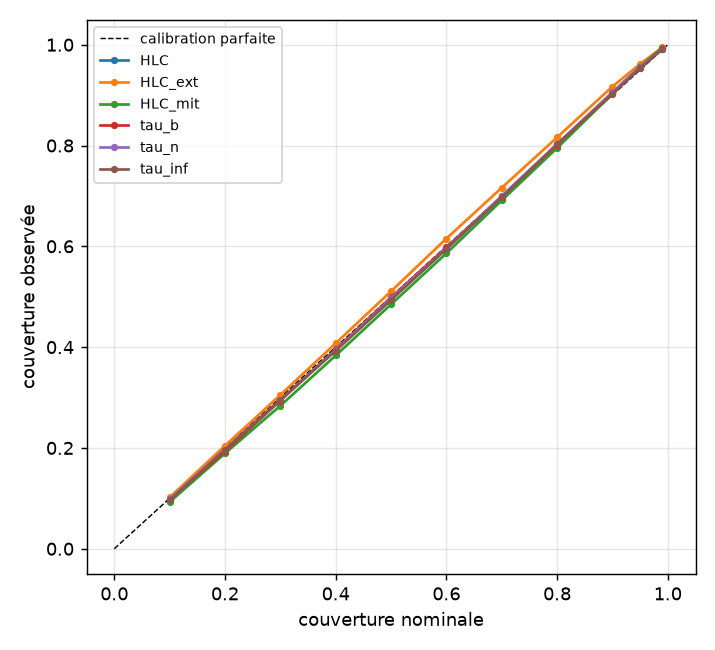

,largeur médiane à 95 %
HLC,97.0
HLC_ext,57.6
HLC_mit,90.5
tau_b,37.5
tau_n,6.8
tau_inf,27.9


,R² médiane exp(mu),R² moyenne exp(mu + s²/2)
tau_b,0.075,0.084
tau_n,0.217,0.221
tau_inf,0.057,0.069


In [33]:
display(Image(filename=str(EVAL_TEST / "reliability.png"), width=420))
display(read_table(EVAL_TEST / "interval_width_95.csv").rename(columns={"0": "largeur médiane à 95 %"}).round(1))
bias_corrected_r2(EVAL_TEST).round(3)

**Lecture.**
- **Calibré jusque dans les queues** : les intervalles à 95 % contiennent la vérité dans 95,3 à 96,2 % des cas, ceux à 99 % dans 99,2 à 99,5 %. Les grandes erreurs de 7.1 surviennent là où le modèle se déclare incertain. Il s'agit d'une calibration **marginale** (sur tout le test) ; elle n'a pas été vérifiée par sous-groupe.
- **Finesse** : 97 W/K à 95 % sur le HLC (±48 W/K), contre 92 W/K pour le modèle sans bruit : la robustesse coûte un peu de finesse.
- **Biais des $\tau$** : la moyenne log-normale ramène le biais de −0,95 h à −0,06 h sur $\tau_b$ et de −0,81 h à −0,02 h sur $\tau_\infty$, et améliore légèrement le $R^2$ (tableau).

### 7.3 Où le modèle se trompe-t-il ?

,n,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
toutes,30000.0,0.391,0.322,0.256,0.075,0.217,0.057
jamais chauffées,2520.0,0.160,0.372,0.104,0.135,0.179,0.102
chauffées,27480.0,0.412,0.318,0.269,0.069,0.220,0.053
énergie D1 [0-10 kWh],2704.0,0.335,0.395,0.204,0.111,0.213,0.079
énergie D2 [10-19 kWh],2784.0,0.410,0.320,0.270,0.095,0.198,0.065
énergie D3 [19-23 kWh],2506.0,0.377,0.265,0.253,0.039,0.185,0.028
énergie D4 [23-27 kWh],2982.0,0.368,0.235,0.249,0.047,0.202,0.036
énergie D5 [27-31 kWh],2689.0,0.425,0.302,0.268,0.073,0.198,0.055
énergie D6 [31-34 kWh],2823.0,0.443,0.315,0.292,0.082,0.225,0.065
énergie D7 [34-36 kWh],2680.0,0.436,0.339,0.284,0.074,0.240,0.065


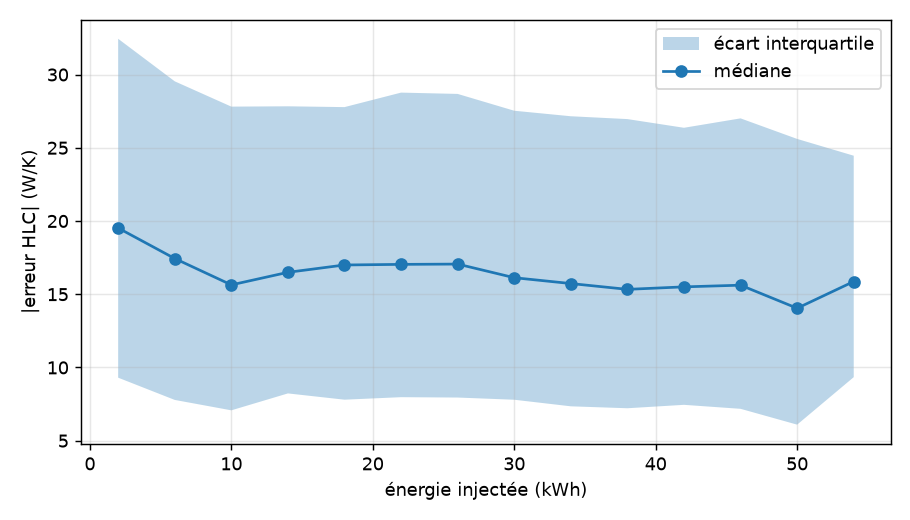

In [34]:
display(read_table(EVAL_TEST / "subgroups_r2.csv").round(3))
display(Image(filename=str(EVAL_TEST / "hlc_error_vs_energy.png"), width=750))

**Lecture.** Les erreurs suivent l'information apportée par l'excitation.
- **Sans chauffe, le HLC est presque inaccessible** ($R^2$ = 0,16 contre 0,41 pour les maisons chauffées). C'est aussi là que l'entraînement avec bruit coûte le plus (0,16 contre 0,24 sans bruit, 6.6 c) : la dérive libre est un signal de faible amplitude.
- **Le HLC s'améliore avec l'énergie injectée**, de 0,34 (1ᵉʳ décile) à 0,46 (dernier), comme annoncé en 3.4. Sur la figure, l'erreur absolue médiane passe d'environ 20 W/K pour les essais les moins énergétiques à 14–16 W/K au-delà de 30 kWh, mais l'écart interquartile reste large à toutes les énergies.
- **$\mathrm{HLC}_{ext}$ suit une courbe en U** : 0,37 sans chauffe, minimum de 0,24 au 4ᵉ décile, 0,36 au dernier. Explication physique cohérente : en évolution libre, $T_{int}$ tend vers la moyenne des températures extérieure et mitoyenne pondérée par $\mathrm{HLC}_{ext}$ et $\mathrm{HLC}_{mit}$. Le sens de la dérive renseigne donc sur la **répartition** des déperditions, pas sur leur total. Une chauffe forte ouvre un autre régime informatif ; les excitations intermédiaires mêlent les deux.
- **$\tau_b$ est mieux estimée sans chauffe** (0,14 contre 0,08) : la relaxation libre révèle les modes lents qu'une chauffe forte masque.

Les meilleures excitations pour le HLC ne sont donc pas les meilleures pour $\mathrm{HLC}_{ext}$ ou $\tau_b$ : concevoir l'essai est un problème **multi-objectif**.

### 7.4 Quelle excitation recommander ?

RMSE du test sur la grille des deux paramètres de l'excitation.

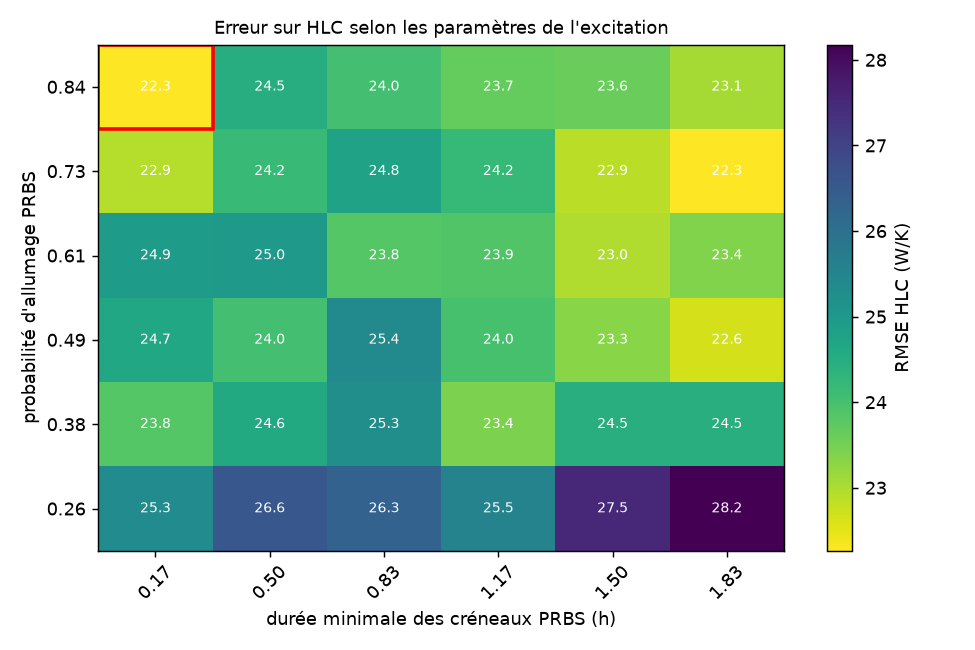

HLC, 3 meilleures cases (RMSE) : {('(0.783, 0.9]', '(-0.0009689, 0.333]'): 22.3, ('(0.667, 0.783]', '(1.667, 2.0]'): 22.3, ('(0.433, 0.55]', '(1.667, 2.0]'): 22.6}


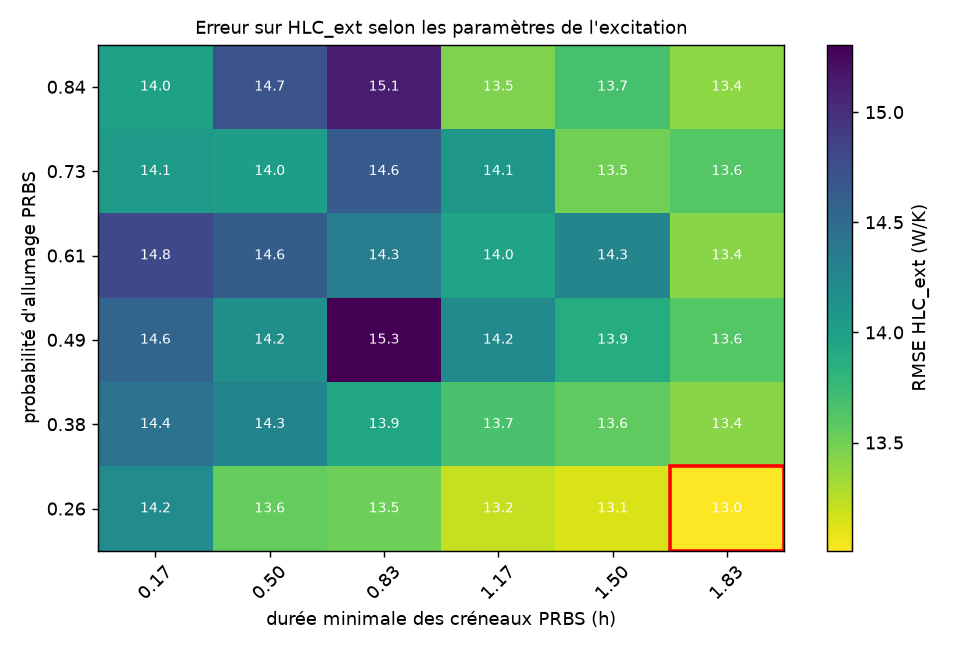

HLC_ext, 3 meilleures cases (RMSE) : {('(0.199, 0.317]', '(1.667, 2.0]'): 13.0, ('(0.199, 0.317]', '(1.333, 1.667]'): 13.1, ('(0.199, 0.317]', '(1.0, 1.333]'): 13.2}


In [35]:
for target in ("HLC", "HLC_ext"):
    display(Image(filename=str(EVAL_TEST / f"excitation_map_{target}.png"), width=560))
    emap = read_table(EVAL_TEST / f"excitation_map_{target}.csv").stack()
    print(f"{target}, 3 meilleures cases (RMSE) :", emap.nsmallest(3).round(1).to_dict())

**Lecture.**
- **HLC** : l'excitation compte (RMSE de 22 à 28 W/K). Les faibles taux d'allumage sont à éviter (0,26 : 25 à 28 W/K). Les meilleurs réglages, autour de 22,3 à 23,4 W/K, combinent un allumage de 0,5 à 0,75 et des créneaux longs (1,5 à 2 h).
- **$\mathrm{HLC}_{ext}$** : effet plus faible (13,0 à 15,3 W/K) et **opposé** : le meilleur réglage est un allumage faible avec des créneaux longs. La case (0,26 ; 1,83 h) est à la fois **la pire pour le HLC et la meilleure pour $\mathrm{HLC}_{ext}$** : le compromis multi-objectif de 7.3 se lit directement.
- **Recommandation** : des **créneaux longs**, qui aident les deux indicateurs, et un taux d'allumage choisi selon la priorité (≈ 0,6 si le HLC prime). Le meilleur réglage étant au bord du domaine simulé (créneaux de 2 h au plus), il faudrait simuler des créneaux plus longs. C'est la démarche d'optimisation de l'excitation de l'article, que notre modèle permet d'évaluer directement.

### 7.5 Robustesse au bruit sur le test

In [36]:
display(read_table(EVAL_TEST / "noise_robustness_final_700k_noise005.csv").round(3))
read_table(EVAL_TEST / "noise_coverage95_final_700k_noise005.csv").round(3)  # couverture à 95 %

,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
bruit (°C),,,,,,
0.00,0.391,0.322,0.256,0.075,0.217,0.057
0.02,0.387,0.312,0.255,0.072,0.214,0.055
0.05,0.372,0.270,0.251,0.061,0.202,0.048
0.10,0.334,0.168,0.241,0.035,0.168,0.030


,HLC,HLC_ext,HLC_mit,tau_b,tau_n,tau_inf
bruit (°C),,,,,,
0.00,0.957,0.962,0.957,0.954,0.956,0.953
0.02,0.957,0.961,0.956,0.953,0.955,0.954
0.05,0.953,0.953,0.956,0.952,0.953,0.953
0.10,0.947,0.934,0.955,0.949,0.948,0.950


**Lecture.** Identique à la validation : HLC 0,391 → 0,387 → 0,372 → 0,334 pour 0 → 0,02 → 0,05 → 0,10 °C. $\mathrm{HLC}_{ext}$ est le plus sensible (0,168 à 0,10 °C), comme l'annonçait l'ACP. La couverture à 95 % reste entre 0,947 et 0,962, sauf $\mathrm{HLC}_{ext}$ à 0,10 °C (0,934).

### 7.6 Limites

1. **Excitations nouvelles : non mesurable.** Seules 13 excitations de test (0,01 % des simulations) sont absentes de l'entraînement (3.6 a), trop peu pour conclure. Le test mesure la généralisation à de nouveaux bâtiments, pas à de nouvelles excitations.
2. **Une typologie, une météo.** Pour un essai réel, il faudrait ré-entraîner sur la météo de l'essai ou fournir les températures extérieures en entrée.
3. **Bruit simplifié** : bruit blanc gaussien sur $T_{int}$ seul ; un capteur réel ajoute biais, dérive, bruit corrélé et temps de réponse, et $U$ est aussi mesuré.
4. **Écart simulation–réalité** : le modèle hérite des hypothèses du simulateur ; sur un bâtiment mal décrit, les intervalles ne sont plus garantis (3.7, existence).
5. **Plafond d'identifiabilité** : environ 40 % de la variance du HLC, d'où des intervalles de ±48 W/K. Ce n'est pas un défaut du modèle mais une limite de l'essai.

## 8. Conclusion et perspectives

**Résultat.** Un CNN-GRU qui, à partir de 8 h de mesures, prédit les six indicateurs avec des intervalles calibrés, respecte les relations physiques par construction (un modèle libre les viole dans 97,5 % des cas) et reste stable jusqu'à 0,10 °C de bruit. Sur le test : HLC à 8,5 % d'erreur relative moyenne ($R^2$ 0,39), $\mathrm{HLC}_{ext}$ 0,32, $\tau_n$ 0,22.

**Ce que nous avons appris.** L'EDA a révélé que le jeu cache des expériences contrôlées (des milliers de maisons partagent la même excitation), et qu'il s'agit d'un problème inverse mal posé : des maisons très différentes produisent des courbes quasi identiques, et ce qui les distingue se joue à l'échelle du bruit d'un capteur (3.7). Cinq leviers indépendants ont ensuite confirmé ce plafond (6.6). **La performance est limitée par l'essai, et c'est sur lui qu'il faut agir.**

**Perspectives**, par priorité :
1. **Concevoir l'excitation avec le modèle.** Le modèle donne en quelques millisecondes une variance a posteriori par indicateur ; on peut noter une excitation candidate par la variance moyenne qu'elle laisse sur des simulations. C'est un plan d'expérience bayésien, multi-objectif (7.3). Premier pas : créneaux de plus de 2 h, au-delà du domaine simulé (7.4).
2. **Enchaîner chauffe et évolution libre** : la chauffe renseigne sur le HLC, l'évolution libre sur la répartition et sur $\tau_b$ (7.3).
3. **Modèle hybride** : traiter l'état initial des parois, principale source d'ambiguïté (3.6 a), comme une variable latente estimée avec les matrices du modèle d'état de coEnergy.
4. **Robustesse** : niveau de bruit tiré au hasard à l'entraînement (configuration `abl_noise_rand010` prête), ensemble de modèles entraînés avec bruit.
5. **Validation hors distribution** : découpage par excitation, météo variable en entrée (conditionnement FiLM, déjà implémenté), puis essai réel de HLC connu.

**Références** : Bishop (1995), *Training with noise is equivalent to Tikhonov regularization*, Neural Computation ; Cranmer, Brehmer & Louppe (2020), PNAS ; Dempster *et al.* (2020), ROCKET ; Forgione & Piga (2021), dynoNet ; Hadamard (1902) ; Nassif *et al.*, article coEnergy (SSRN 6928008) ; Papamakarios & Murray (2016) ; Perez *et al.* (2018), FiLM ; Pi & Peterson (1994), test Delta ; Seitzer *et al.* (2022), $\beta$-NLL ; Talts *et al.* (2018), SBC ; Tan *et al.* (2021), régression de séries temporelles ; Baasch *et al.* (2021).